# Progetto di Data Mining  
## Premier League Event Data 2020-2021  

L'obiettivo di questo progetto è analizzare un dataset non documentato contenente gli eventi delle partite della Premier League 2020-2021.

Il lavoro è stato organizzato in quattro fasi principali:

1. interpretazione e descrizione del dataset;  
2. ricostruzione delle partite e feature extraction;  
3. analisi esplorativa dei dati (EDA);  
4. classificazione del risultato della partita.  

Il dataset originale è strutturato a livello di evento, pertanto è stato necessario trasformarlo in un dataset aggregato a livello di squadra-partita, al fine di rendere possibile l’analisi statistica e l’applicazione di modelli di machine learning.

In [ ]:
# Import delle librerie necessarie

import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tabulate import tabulate
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from xgboost import XGBClassifier

# Impostazioni grafiche e gestione warning
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)  

## Caricamento e pulizia iniziale del dataset

In questa fase viene caricato il dataset originale degli eventi della Premier League 2020-2021 a partire da un file CSV.

Successivamente viene effettuata una prima operazione di pulizia dei dati, rimuovendo eventuali colonne non informative, come ad esempio la colonna *Unnamed: 0*, generata automaticamente durante l’esportazione del file.

Infine, viene effettuata una prima esplorazione del dataset per verificarne la struttura, analizzando:
- la dimensione (numero di righe e colonne),
- le prime osservazioni,
- l’elenco delle variabili presenti.

In [2]:
# Caricamento del dataset
df = pd.read_csv("20-21_plEventsData.csv", low_memory=False)

# Rimozione di eventuali colonne non informative
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

# Dimensione del dataset (righe, colonne)
df.shape 

(607656, 34)

Il dataset contiene oltre 600.000 eventi e circa 34 variabili, confermando la granularità dei dati.

In [3]:
# Visualizzazione delle prime righe
pd.set_option('display.max_columns', None)
df.head(10) 

,id,eventId,minute,second,teamId,x,y,expandedMinute,qualifiers,satisfiedEventsTypes,isTouch,period_value,period_displayName,type_value,type_displayName,outcomeType_value,outcomeType_displayName,playerId,endX,endY,relatedEventId,relatedPlayerId,goalMouthZ,goalMouthY,isShot,blockedX,blockedY,cardType_value,cardType_displayName,isGoal,name,position,shirtNo,isOwnGoal
0,2.253487e+09,2,0,0.0,32,0.0,0.0,0,[],[],False,1,FirstHalf,32,Start,1,Successful,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2.253487e+09,1000003,0,0.0,184,0.0,0.0,0,[],[],False,1,FirstHalf,32,Start,1,Successful,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2.253488e+09,1000004,0,0.0,184,50.3,50.3,0,"[{'type': {'value': 213, 'displayName': 'Angle...","[90, 116, 29, 34, 214, 217]",True,1,FirstHalf,1,Pass,1,Successful,79050.0,30.5,50.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Ashley Westwood,MC,18.0,NaN
3,2.253488e+09,1000005,0,2.0,184,29.6,53.4,0,"[{'type': {'value': 178, 'displayName': 'Stand...","[90, 116, 29, 35, 37, 215, 217]",True,1,FirstHalf,1,Pass,1,Successful,131464.0,36.4,23.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,James Tarkowski,DC,5.0,NaN
4,2.253488e+09,1000006,0,7.0,184,41.3,18.4,0,"[{'type': {'value': 1, 'displayName': 'Longbal...","[90, 118, 116, 122, 123, 126, 204, 38, 45, 35,...",True,1,FirstHalf,1,Pass,1,Successful,80067.0,86.0,73.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Matthew Lowton,DR,2.0,NaN
5,2.253488e+09,1000007,0,11.0,184,86.0,73.1,0,"[{'type': {'value': 55, 'displayName': 'Relate...","[90, 6, 89, 9, 1, 3, 12]",True,1,FirstHalf,13,MissedShots,1,Successful,93473.0,NaN,NaN,1000006.0,80067.0,75.0,57.1,True,NaN,NaN,NaN,NaN,NaN,Robbie Brady,ML,12.0,NaN
6,2.253488e+09,4,0,44.0,32,4.8,49.6,0,"[{'type': {'value': 140, 'displayName': 'PassE...","[90, 116, 123, 126, 35, 37, 215, 217]",True,1,FirstHalf,1,Pass,1,Successful,79554.0,42.2,30.9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,David de Gea,GK,1.0,NaN
7,2.253488e+09,5,0,47.0,32,42.2,30.9,0,"[{'type': {'value': 140, 'displayName': 'PassE...","[90, 117, 119, 28, 34, 37, 215, 217]",True,1,FirstHalf,1,Pass,0,Unsuccessful,123761.0,37.6,28.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Bruno Fernandes,AMC,18.0,NaN
8,2.253488e+09,1000009,0,48.0,184,60.4,71.9,0,"[{'type': {'value': 178, 'displayName': 'Stand...","[90, 100, 55]",True,1,FirstHalf,8,Interception,1,Successful,93473.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robbie Brady,ML,12.0,NaN
9,2.253488e+09,6,0,48.0,32,38.5,27.6,0,"[{'type': {'value': 178, 'displayName': 'Stand...",[90],True,1,FirstHalf,61,BallTouch,1,Successful,97752.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Paul Pogba,DMC,6.0,NaN


In [4]:
# Elenco delle colonne del dataset
pd.DataFrame(df.columns, columns=["Colonne"])

,Colonne
0,id
1,eventId
2,minute
3,second
4,teamId
5,x
6,y
7,expandedMinute
8,qualifiers
9,satisfiedEventsTypes


In [5]:
# Numero totale di colonne
len(df.columns)

34

## Struttura del dataset

Il dataset è di tipo event-based e descrive in modo dettagliato tutte le azioni di gioco avvenute durante le partite.  
Ogni riga rappresenta un singolo evento ed è caratterizzata da un insieme di variabili che descrivono il contesto temporale, spaziale e tecnico dell’azione.

Di seguito vengono descritte tutte le variabili presenti nel dataset:

- *id*: identificativo univoco della riga;
- *eventId*: identificativo della tipologia di evento;
- *minute*: minuto di gioco in cui avviene l’evento;
- *second*: secondo all’interno del minuto;
- *teamId*: identificativo numerico della squadra che effettua l’evento;
- *x, y*: coordinate di inizio dell’evento sul campo;
- *expandedMinute*: minuto esteso (utile per includere recupero e tempi supplementari);
- *qualifiers*: informazioni aggiuntive sull’evento (es. tipo di passaggio, condizioni particolari);
- *satisfiedEventsTypes*: lista di eventi soddisfatti associati all’azione;
- *isTouch*: indica se l’evento è un tocco di palla;
- *period_value*: identificativo numerico del periodo di gioco;
- *period_displayName*: descrizione del periodo (es. primo tempo, secondo tempo);
- *type_value*: codice numerico del tipo di evento;
- *type_displayName*: descrizione del tipo di evento (Pass, Shot, Tackle, ecc.);
- *outcomeType_value*: codice numerico dell’esito dell’evento;
- *outcomeType_displayName*: descrizione dell’esito (riuscito, fallito, ecc.);
- *playerId*: identificativo del giocatore coinvolto;
- *endX, endY*: coordinate finali dell’evento (se applicabile);
- *relatedEventId*: identificativo di un evento correlato;
- *relatedPlayerId*: identificativo di un giocatore correlato all’evento;
- *goalMouthZ, goalMouthY*: coordinate della porta (utili per analizzare i tiri);
- *isShot*: indica se l’evento è un tiro;
- *blockedX, blockedY*: coordinate del punto in cui un tiro è stato bloccato;
- *cardType_value*: codice numerico del tipo di cartellino;
- *cardType_displayName*: descrizione del cartellino (giallo, rosso);
- *isGoal*: indica se l’evento ha portato a un goal;
- *name*: nome del giocatore;
- *position*: ruolo del giocatore in campo;
- *shirtNo*: numero di maglia del giocatore;
- *isOwnGoal*: indica se il goal è un’autorete.

Questa struttura consente una rappresentazione estremamente dettagliata delle azioni di gioco, ma non è direttamente adatta ad analisi a livello di partita.

Per questo motivo, nelle fasi successive, il dataset viene trasformato aggregando gli eventi a livello di squadra-partita, costruendo feature sintetiche utili per l’analisi e per i modelli di classificazione.

## Identificazione delle squadre

Nel dataset le squadre sono identificate tramite un codice numerico (`teamId`), mentre il nome della squadra non è esplicitamente presente.

Per rendere i dati più interpretabili, è stata costruita una mappatura tra `teamId` e il nome della squadra (`team_name`).  

Questa associazione è stata ricavata analizzando i giocatori presenti negli eventi e riconducendoli alle rispettive squadre.
Per ciascun teamId vengono mostrati alcuni nomi di giocatori associati, così da controllare che l’associazione sia coerente con le squadre reali.
La sostituzione della variabile teamId con `team_name` consente di migliorare la leggibilità del dataset e facilita le successive operazioni di aggregazione e analisi.

In [6]:
# =========================================================
# ANALISI PRELIMINARE: associazione teamId - squadra
# =========================================================

teamid_players = (
    df[["teamId", "name"]]
    .dropna()
    .drop_duplicates()
    .groupby("teamId")["name"]
    .apply(lambda x: ", ".join(x.head(3)))
    .reset_index()
    .rename(columns={"name": "players_sample"})
    .sort_values("teamId")
)

teamid_players  

,teamId,players_sample
0,13,"Kieran Tierney, Granit Xhaka, Alexandre Lacazette"
1,14,"Timothy Castagne, Wilfred Ndidi, Çaglar Söyüncü"
2,15,"Marcos Alonso, Ruben Loftus-Cheek, Kurt Zouma"
3,18,"James Ward-Prowse, Jack Stephens, Oriol Romeu"
4,19,"Luke Ayling, Pablo Hernández, Stuart Dallas"
5,23,"Isaac Hayden, Jonjo Shelvey, Andy Carroll"
6,24,"Matthew Cash, Ezri Konsa Ngoyo, Emiliano Martínez"
7,26,"Naby Keita, Joseph Gomez, Jordan Henderson"
8,29,"Tomas Soucek, Lukasz Fabianski, Jarrod Bowen"
9,30,"Dele Alli, Eric Dier, Ben Davies"


In [7]:

team_map = {
    13: "Arsenal",
    14: "Leicester City",
    15: "Chelsea",
    18: "Southampton",
    19: "Leeds United",
    23: "Newcastle United",
    24: "Aston Villa",
    26: "Liverpool",
    29: "West Ham United",
    30: "Tottenham Hotspur",
    31: "Everton",
    32: "Manchester United",
    161: "Wolverhampton Wanderers",
    162: "Crystal Palace",
    163: "Sheffield United",
    167: "Manchester City",
    170: "Fulham",
    175: "West Bromwich Albion",
    184: "Burnley",
    211: "Brighton & Hove Albion"
}

# 1. Mappatura

df["team_name"] = df["teamId"].map(team_map)

# 2. Rimozione
df = df.drop(columns=["teamId"])

# 3. Output
pd.DataFrame(
    sorted(df["team_name"].dropna().unique()),
    columns=["Squadre"]
)
 

,Squadre
0,Arsenal
1,Aston Villa
2,Brighton & Hove Albion
3,Burnley
4,Chelsea
5,Crystal Palace
6,Everton
7,Fulham
8,Leeds United
9,Leicester City


In [8]:
#numero squadre 
df["team_name"].nunique()  

20

Dall’analisi dei giocatori associati a ciascun identificativo emerge una corrispondenza coerente tra teamId e squadre.

Questo conferma la correttezza della mappatura adottata, permettendo di sostituire definitivamente l’identificativo numerico con il nome della squadra e migliorare l’interpretabilità del dataset nelle successive fasi di analisi.

## Verifica del numero di partite

Per verificare che il dataset contenga correttamente tutte le partite della stagione, vengono analizzati gli eventi di tipo `Start` relativi al primo tempo (`FirstHalf`).

Ogni partita genera due eventi di inizio del primo tempo, uno per ciascuna squadra.  

Pertanto, il numero totale di partite può essere calcolato dividendo per due il numero totale di eventi `Start` del primo tempo.

In [9]:
start_events = df[df["type_displayName"] == "Start"].copy()
first_half_start = start_events[start_events["period_displayName"] == "FirstHalf"].copy()

numero_partite = int(len(first_half_start) / 2)
numero_partite

380

In [10]:
start_events["period_displayName"].value_counts()  

period_displayName
FirstHalf     760
SecondHalf    760
Name: count, dtype: int64

L’analisi degli eventi di inizio del primo tempo mostra la presenza di 760 eventi `Start` nel `FirstHalf`.

Poiché ogni partita coinvolge due squadre, il numero totale di partite è pari a:

760 / 2 = 380

Questo valore è perfettamente coerente con la struttura reale della Premier League 2020-2021, composta da 20 squadre e 380 partite complessive.

## Ricostruzione delle partite

Il dataset originale non contiene un identificatore esplicito della partita.

Per questo motivo, è necessario ricostruire le partite a partire dagli eventi di tipo `Start` del primo tempo (`FirstHalf`).

Poiché ogni partita presenta due eventi `Start` nel `FirstHalf`, uno per ciascuna squadra, è possibile ricostruire la tabella delle partite accoppiando questi eventi a due a due.

In [11]:
start_first_half = df[
    (df["type_displayName"] == "Start") &
    (df["period_displayName"] == "FirstHalf")
].copy().reset_index(drop=True)

matches = []

for i in range(0, len(start_first_half), 2):
    team1 = start_first_half.loc[i, "team_name"]
    team2 = start_first_half.loc[i + 1, "team_name"]

    matches.append({
        "match_id": i // 2 + 1,
        "team1": team1,
        "team2": team2
    })

matches_df = pd.DataFrame(matches)

matches_df.head() 

,match_id,team1,team2
0,1,Manchester United,Burnley
1,2,Aston Villa,Manchester City
2,3,Southampton,Crystal Palace
3,4,Arsenal,Fulham
4,5,Liverpool,Leeds United


In [12]:
len(matches_df) 

380

In [13]:
matches_df["team1"].nunique(), matches_df["team2"].nunique() 

(20, 20)

La tabella `matches_df` rappresenta la ricostruzione delle partite della stagione.

Ogni riga contiene:
- un identificatore univoco della partita (`match_id`);
- la prima squadra (`team1`);
- la seconda squadra (`team2`).

La procedura ha permesso di ricostruire correttamente 380 partite, in linea con il numero atteso per la stagione di Premier League 2020-2021.

Inoltre, il fatto che siano presenti 20 squadre distinte sia nella colonna `team1` che nella colonna `team2` conferma la correttezza della ricostruzione.

## Assegnazione del match_id agli eventi

Una volta ricostruita la tabella delle partite, è necessario associare ogni evento del dataset alla partita di appartenenza.

Questa operazione consente di trasformare il dataset da una struttura puramente event-based a una struttura aggregabile a livello di squadra e partita.

L’assegnazione del `match_id` avviene identificando gli eventi di inizio del primo tempo e utilizzandoli come riferimento per suddividere sequenzialmente il dataset nelle diverse partite.

In [14]:
df = df.reset_index(drop=True)

start_mask = (
    (df["type_displayName"] == "Start") &
    (df["period_displayName"] == "FirstHalf")
)

start_indices = df[start_mask].index.tolist()

match_ids = []
current_match = 0
next_start_pointer = 0

for i in range(len(df)):
    if next_start_pointer < len(start_indices) and i == start_indices[next_start_pointer]:
        current_match += 1
        next_start_pointer += 2

    match_ids.append(current_match)

df["match_id"] = match_ids

df["match_id"].nunique()  

380

In [15]:
df[["match_id", "team_name", "type_displayName", "period_displayName"]].head(10) 

,match_id,team_name,type_displayName,period_displayName
0,1,Manchester United,Start,FirstHalf
1,1,Burnley,Start,FirstHalf
2,1,Burnley,Pass,FirstHalf
3,1,Burnley,Pass,FirstHalf
4,1,Burnley,Pass,FirstHalf
5,1,Burnley,MissedShots,FirstHalf
6,1,Manchester United,Pass,FirstHalf
7,1,Manchester United,Pass,FirstHalf
8,1,Burnley,Interception,FirstHalf
9,1,Manchester United,BallTouch,FirstHalf


L’assegnazione del `match_id` a ciascun evento rende possibile aggregare le informazioni a livello di partita.

Questo passaggio è fondamentale, poiché consente di costruire un dataset in cui ogni riga rappresenta la prestazione di una squadra in una determinata partita.

## Feature Extraction

Il dataset originale è strutturato a livello di evento, in cui ogni riga rappresenta un singolo evento di gioco. Per poter applicare tecniche di analisi statistica e classificazione, è stato necessario trasformarlo in una struttura aggregata a livello di partita e squadra. In questa fase sono state costruite feature numeriche in grado di descrivere la prestazione di ogni squadra in ciascuna partita, includendo variabili come il numero di passaggi, il numero di tiri, falli, contrasti, intercettazioni, recuperi palla, duelli aerei e dribbling. A queste si aggiungono feature spaziali, calcolate come media delle coordinate degli eventi, utili a rappresentare il comportamento medio della squadra sul campo. Non tutti gli eventi presenti nel dataset sono stati utilizzati: sono stati selezionati esclusivamente quelli ritenuti più informativi per descrivere la prestazione e influenzare il risultato della partita. In particolare, sono stati considerati eventi legati alla fase offensiva (tiri e goal), alla costruzione del gioco e al possesso (passaggi e dribbling), alla fase difensiva (contrasti, intercettazioni e recuperi) e alla disciplina (falli e cartellini). Eventi meno rilevanti, ridondanti o troppo frequenti, come semplici tocchi di palla o eventi strutturali, sono stati esclusi per ridurre il rumore e migliorare l’efficacia dei modelli di classificazione.


In [16]:
event_features = [
    "Pass",
    "Goal",
    "MissedShots",
    "SavedShot",
    "ShotOnPost",
    "Foul",
    "Tackle",
    "Interception",
    "Clearance",
    "BallRecovery",
    "Aerial",
    "TakeOn",
    "Card"
]

all_teams_matches = []

for _, row in matches_df.iterrows():
    all_teams_matches.append({
        "match_id": row["match_id"],
        "team_name": row["team1"]
    })
    all_teams_matches.append({
        "match_id": row["match_id"],
        "team_name": row["team2"]
    })

all_teams_matches_df = pd.DataFrame(all_teams_matches)

all_teams_matches_df.head(20) 

,match_id,team_name
0,1,Manchester United
1,1,Burnley
2,2,Aston Villa
3,2,Manchester City
4,3,Southampton
5,3,Crystal Palace
6,4,Arsenal
7,4,Fulham
8,5,Liverpool
9,5,Leeds United


In [17]:
features_df = (
    df[df["type_displayName"].isin(event_features)]
    .groupby(["match_id", "team_name", "type_displayName"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

# Garantiamo 2 squadre per match
features_df = all_teams_matches_df.merge(
    features_df,
    on=["match_id", "team_name"],
    how="left"
).fillna(0)
features_df.head(20)

,match_id,team_name,Aerial,BallRecovery,Card,Clearance,Foul,Goal,Interception,MissedShots,Pass,SavedShot,ShotOnPost,Tackle,TakeOn
0,1,Manchester United,34,60,2,19,28,1,10,2,606,10,0,12,12
1,1,Burnley,34,57,1,19,28,0,11,6,374,5,0,5,8
2,2,Aston Villa,32,38,4,29,19,0,15,4,308,7,0,14,14
3,2,Manchester City,32,50,0,11,19,2,11,6,674,19,1,14,23
4,3,Southampton,59,44,1,18,25,0,9,3,638,6,0,28,13
5,3,Crystal Palace,59,60,2,23,25,1,12,2,285,2,0,15,18
6,4,Arsenal,13,42,2,11,24,3,18,3,666,6,1,12,10
7,4,Fulham,13,46,2,11,24,0,10,2,560,3,0,11,12
8,5,Liverpool,26,71,1,11,15,4,14,3,490,15,0,13,35
9,5,Leeds United,26,56,0,35,15,3,12,1,504,2,0,34,15


### Costruzione e allineamento delle feature

Le feature vengono inizialmente costruite aggregando gli eventi selezionati per ciascuna squadra e partita.  
In particolare, per ogni coppia (match_id, team_name) viene calcolato il numero di occorrenze di ciascun tipo di evento.

Tuttavia, questa operazione include solo le squadre che presentano almeno un evento tra quelli selezionati.

Per garantire una rappresentazione completa del dataset, le feature vengono successivamente unite alla struttura contenente tutte le squadre per ogni partita.  
In questo modo si assicura che ogni match sia rappresentato da entrambe le squadre, assegnando valore zero alle feature mancanti.

Questo passaggio consente di ottenere un dataset finale coerente e completo, pronto per le successive fasi di analisi e modellazione.

In [18]:
len(features_df)  

760

Il dataset risultante contiene 760 righe, corrispondenti a tutte le combinazioni squadra-partita (380 partite × 2 squadre).

Per ogni squadra in ogni partita sono state calcolate le feature basate sul conteggio degli eventi.

Questa trasformazione consente di passare da una struttura event-based a una struttura adatta per l’analisi statistica e l’applicazione di modelli di machine learning.   

In [19]:
spatial_features = (
    df.groupby(["match_id", "team_name"])[["x", "y", "endX", "endY"]]
    .mean()
    .reset_index()
    .rename(columns={
        "x": "mean_x",
        "y": "mean_y",
        "endX": "mean_endX",
        "endY": "mean_endY"
    })
)

spatial_features.head()   

,match_id,team_name,mean_x,mean_y,mean_endX,mean_endY
0,1,Burnley,44.071298,53.667939,52.765152,55.199747
1,1,Manchester United,47.421763,46.811719,54.481021,48.712440
2,2,Aston Villa,37.148997,52.906522,47.925444,57.001183
3,2,Manchester City,53.136611,49.748536,57.383866,52.231977
4,3,Crystal Palace,44.892026,53.337002,58.040575,54.395847


In [20]:
features_df = features_df.merge(
    spatial_features,
    on=["match_id", "team_name"],
    how="left"
)

features_df.head() 

,match_id,team_name,Aerial,BallRecovery,Card,Clearance,Foul,Goal,Interception,MissedShots,Pass,SavedShot,ShotOnPost,Tackle,TakeOn,mean_x,mean_y,mean_endX,mean_endY
0,1,Manchester United,34,60,2,19,28,1,10,2,606,10,0,12,12,47.421763,46.811719,54.481021,48.712440
1,1,Burnley,34,57,1,19,28,0,11,6,374,5,0,5,8,44.071298,53.667939,52.765152,55.199747
2,2,Aston Villa,32,38,4,29,19,0,15,4,308,7,0,14,14,37.148997,52.906522,47.925444,57.001183
3,2,Manchester City,32,50,0,11,19,2,11,6,674,19,1,14,23,53.136611,49.748536,57.383866,52.231977
4,3,Southampton,59,44,1,18,25,0,9,3,638,6,0,28,13,44.835616,46.926765,51.305649,49.084733


Per arricchire ulteriormente la rappresentazione delle squadre, sono state introdotte alcune feature spaziali basate sulla posizione degli eventi sul campo.

In particolare, per ogni coppia (match_id, team_name) vengono calcolate:
- la posizione media di inizio evento (mean_x, mean_y);
- la posizione media di fine evento (mean_endx, mean_endy).

Queste variabili rappresentano una sintesi del comportamento spaziale della squadra durante la partita, permettendo di catturare:
- il posizionamento medio sul campo;
- la tendenza a giocare in zone più offensive o difensive;
- la direzione e lo sviluppo medio delle azioni.

Successivamente, tali feature vengono integrate nel dataset principale tramite un'operazione di merge, in modo da ottenere una rappresentazione più completa di ogni squadra per ogni partita.

Questo passaggio consente di combinare informazioni quantitative sugli eventi con informazioni spaziali, migliorando il potenziale informativo delle feature per i modelli di classificazione. 

Nel tuo dataset, x e y rappresentano la posizione sul campo dove avviene un evento.

👉 Sono coordinate normalizzate su un campo da calcio.

⸻

📍 Interpretazione standard
	•	x → direzione orizzontale (lunghezza campo)
	•	y → direzione verticale (larghezza campo)

⸻

🔹 Asse X (0 → 100)

👉 indica quanto sei vicino alla porta avversaria
	•	0 → vicino alla propria porta
	•	50 → centrocampo
	•	100 → vicino alla porta avversaria

⸻

🔹 Asse Y (0 → 100)

👉 indica la posizione laterale
	•	0 → fascia sinistra
	•	50 → centro campo (in larghezza)
	•	100 → fascia destra

x
y
Significato
20
50
difesa centrale
50
50
centrocampo
80
50
zona offensiva centrale
80
10
attacco sulla fascia sinistra
80
90
attacco sulla fascia destra  

## Aggiunta della squadra avversaria

Per ogni squadra in ogni partita, viene aggiunta l’informazione relativa alla squadra avversaria.

Questa variabile è utile per confrontare direttamente le prestazioni delle due squadre all’interno della stessa partita e per arricchire il dataset finale con un’informazione contestuale rilevante.  

In [21]:
opponent_rows = []

for _, row in matches_df.iterrows():
    opponent_rows.append({
        "match_id": row["match_id"],
        "team_name": row["team1"],
        "opponent": row["team2"]
    })
    opponent_rows.append({
        "match_id": row["match_id"],
        "team_name": row["team2"],
        "opponent": row["team1"]
    })

opponent_df = pd.DataFrame(opponent_rows)

features_df = features_df.merge(
    opponent_df,
    on=["match_id", "team_name"],
    how="left"
)

features_df.head() 

,match_id,team_name,Aerial,BallRecovery,Card,Clearance,Foul,Goal,Interception,MissedShots,Pass,SavedShot,ShotOnPost,Tackle,TakeOn,mean_x,mean_y,mean_endX,mean_endY,opponent
0,1,Manchester United,34,60,2,19,28,1,10,2,606,10,0,12,12,47.421763,46.811719,54.481021,48.712440,Burnley
1,1,Burnley,34,57,1,19,28,0,11,6,374,5,0,5,8,44.071298,53.667939,52.765152,55.199747,Manchester United
2,2,Aston Villa,32,38,4,29,19,0,15,4,308,7,0,14,14,37.148997,52.906522,47.925444,57.001183,Manchester City
3,2,Manchester City,32,50,0,11,19,2,11,6,674,19,1,14,23,53.136611,49.748536,57.383866,52.231977,Aston Villa
4,3,Southampton,59,44,1,18,25,0,9,3,638,6,0,28,13,44.835616,46.926765,51.305649,49.084733,Crystal Palace


## Costruzione di feature derivate

Oltre alle feature ottenute direttamente dal conteggio degli eventi, vengono costruite alcune variabili derivate utili a descrivere in modo più sintetico e informativo la prestazione offensiva della squadra.

In particolare vengono calcolate:
- il numero totale di tiri;
- il numero di tiri in porta;
- il numero di goal segnati.

Nel caso dei goal, il calcolo viene successivamente corretto tenendo conto delle eventuali autoreti presenti nel dataset.

In [22]:
features_df["total_shots"] = (
    features_df["Goal"] +
    features_df["MissedShots"] +
    features_df["SavedShot"] +
    features_df["ShotOnPost"]
)

features_df["shots_on_target"] = (
    features_df["Goal"] +
    features_df["SavedShot"] +
    features_df["ShotOnPost"]
)

# =========================
# GOAL CORRETTI (GESTIONE AUTORETI)
# =========================

goal_events = df[df["type_displayName"] == "Goal"].copy()

# aggiungiamo l'avversario agli eventi di goal
goal_events = goal_events.merge(
    opponent_df,
    on=["match_id", "team_name"],
    how="left"
)

# se è autorete, il goal va assegnato all'avversario
goal_events["scoring_team"] = np.where(
    goal_events["isOwnGoal"] == True,
    goal_events["opponent"],
    goal_events["team_name"]
)

# conteggio corretto dei goal per partita e squadra
goals_corrected = (
    goal_events.groupby(["match_id", "scoring_team"])
    .size()
    .reset_index(name="goals_corrected")
    .rename(columns={"scoring_team": "team_name"})
)

# merge dei goal corretti nel dataset finale
features_df = features_df.drop(columns=["goals"], errors="ignore")

features_df = features_df.merge(
    goals_corrected,
    on=["match_id", "team_name"],
    how="left"
)

features_df["goals"] = features_df["goals_corrected"].fillna(0).astype(int)

features_df = features_df.drop(columns=["goals_corrected"])

features_df.head()

,match_id,team_name,Aerial,BallRecovery,Card,Clearance,Foul,Goal,Interception,MissedShots,Pass,SavedShot,ShotOnPost,Tackle,TakeOn,mean_x,mean_y,mean_endX,mean_endY,opponent,total_shots,shots_on_target,goals
0,1,Manchester United,34,60,2,19,28,1,10,2,606,10,0,12,12,47.421763,46.811719,54.481021,48.712440,Burnley,13,11,1
1,1,Burnley,34,57,1,19,28,0,11,6,374,5,0,5,8,44.071298,53.667939,52.765152,55.199747,Manchester United,11,5,0
2,2,Aston Villa,32,38,4,29,19,0,15,4,308,7,0,14,14,37.148997,52.906522,47.925444,57.001183,Manchester City,11,7,0
3,2,Manchester City,32,50,0,11,19,2,11,6,674,19,1,14,23,53.136611,49.748536,57.383866,52.231977,Aston Villa,28,22,2
4,3,Southampton,59,44,1,18,25,0,9,3,638,6,0,28,13,44.835616,46.926765,51.305649,49.084733,Crystal Palace,9,6,0


### Analisi del possesso palla (proxy)

Per arricchire la rappresentazione delle partite, viene introdotta una stima del possesso palla.

Poiché il dataset non contiene direttamente informazioni temporali sul possesso, è stata definita una misura proxy basata su eventi che riflettono il controllo del gioco, come passaggi, recuperi di palla e azioni individuali.

L’obiettivo è quello di catturare in modo indiretto il dominio territoriale e la capacità di una squadra di gestire il pallone durante la partita.

In [23]:
# ===============================
# POSSESSO PALLA 
# ===============================

# misura proxy del possesso basata su eventi di controllo del gioco
features_df["possession_proxy"] = (
    features_df["Pass"] +
    features_df["BallRecovery"] +
    features_df["TakeOn"] +
    features_df["Aerial"]
)

# differenza di possesso rispetto all'avversario nella stessa partita
features_df["possession_diff"] = features_df.groupby("match_id")["possession_proxy"].transform(
    lambda x: x - x.iloc[::-1].values
)

# quota relativa di possesso sul totale della partita
total_possession = features_df.groupby("match_id")["possession_proxy"].transform("sum")
features_df["possession_ratio"] = features_df["possession_proxy"] / (total_possession + 1)

# feature binaria: vantaggio di possesso
features_df["possession_advantage"] = (features_df["possession_diff"] > 0).astype(int)

# controllo rapido
features_df[[
    "match_id", "team_name", "Pass", "BallRecovery", "TakeOn", "Aerial",
    "possession_proxy", "possession_diff", "possession_ratio", "possession_advantage"
]].head(10)  

,match_id,team_name,Pass,BallRecovery,TakeOn,Aerial,possession_proxy,possession_diff,possession_ratio,possession_advantage
0,1,Manchester United,606,60,12,34,712,239,0.600337,1
1,1,Burnley,374,57,8,34,473,-239,0.398820,0
2,2,Aston Villa,308,38,14,32,392,-387,0.334471,0
3,2,Manchester City,674,50,23,32,779,387,0.664676,1
4,3,Southampton,638,44,13,59,754,332,0.640612,1
5,3,Crystal Palace,285,60,18,59,422,-332,0.358539,0
6,4,Arsenal,666,42,10,13,731,100,0.536317,1
7,4,Fulham,560,46,12,13,631,-100,0.462949,0
8,5,Liverpool,490,71,35,26,622,21,0.508170,1
9,5,Leeds United,504,56,15,26,601,-21,0.491013,0


La misura del possesso è stata costruita combinando diverse tipologie di eventi:

- *Pass*: indicano il mantenimento del possesso e la costruzione del gioco;
- *BallRecovery*: rappresentano la riconquista del pallone;
- *TakeOn*: riflettono la capacità di avanzare mantenendo il controllo;
- *Aerial*: modellano le situazioni di contesa del possesso.

A partire da questa proxy (possession_proxy), sono state derivate ulteriori variabili:

- *possession_diff*: misura il divario di possesso tra le due squadre nella stessa partita;
- *possession_ratio*: normalizza il possesso rispetto al totale della partita;
- *possession_advantage*: variabile binaria che indica quale squadra ha avuto maggiore controllo del gioco.

Queste feature consentono di rappresentare il possesso in modo coerente con i dati disponibili, senza introdurre informazioni direttamente legate al risultato della partita, contribuendo così a migliorare la capacità predittiva dei modelli.  

### Correzione del calcolo dei goal (gestione autoreti)

Nel dataset è presente la variabile isOwnGoal, che consente di identificare gli eventi di autorete.

In particolare:
- se isOwnGoal = False, il goal viene assegnato normalmente alla squadra associata all’evento;
- se isOwnGoal = True, il goal è un’autorete e viene quindi assegnato alla squadra avversaria.

Per gestire correttamente questo aspetto, è stato necessario:
1. associare a ciascun evento di goal la squadra avversaria;
2. creare una nuova variabile (scoring_team) che identifica la squadra a cui attribuire effettivamente il goal;
3. ricalcolare il numero di goal per partita e squadra sulla base di questa logica.

Questo passaggio è fondamentale per ottenere:
- un conteggio corretto dei goal segnati;
- una corretta determinazione dei risultati delle partite;
- una ricostruzione accurata della classifica finale del campionato.  

## Definizione del risultato della partita

Per ciascuna squadra in ogni partita, viene determinato il risultato finale della partita in termini di:
- vittoria (win),
- pareggio (draw),
- sconfitta (loss).

Il risultato viene calcolato confrontando il numero di goal segnati dalle due squadre nella stessa partita.

Questa variabile rappresenta il target per i successivi modelli di classificazione.

In [24]:
results = []

for match_id in features_df["match_id"].unique():
    
    match_rows = features_df[features_df["match_id"] == match_id][["team_name", "goals"]].reset_index(drop=True)
    
    if len(match_rows) != 2:
        continue
    
    team_a = match_rows.loc[0, "team_name"]
    goals_a = match_rows.loc[0, "goals"]
    
    team_b = match_rows.loc[1, "team_name"]
    goals_b = match_rows.loc[1, "goals"]
    
    if goals_a > goals_b:
        results.append({"match_id": match_id, "team_name": team_a, "result": "Vittoria"})
        results.append({"match_id": match_id, "team_name": team_b, "result": "Sconfitta"})
        
    elif goals_a < goals_b:
        results.append({"match_id": match_id, "team_name": team_a, "result": "Sconfitta"})
        results.append({"match_id": match_id, "team_name": team_b, "result": "Vittoria"})
        
    else:
        results.append({"match_id": match_id, "team_name": team_a, "result": "Pareggio"})
        results.append({"match_id": match_id, "team_name": team_b, "result": "Pareggio"})

results_df = pd.DataFrame(results)

#pulizia prima del merge 
#fa sì che:
#	•	se hai già runnato prima → cancella colonne vecchie
#	•	se NON ci sono → non crasha (errors="ignore")

features_df = features_df.drop(columns=["result", "result_x", "result_y"], errors="ignore")

features_df = features_df.merge(
    results_df,
    on=["match_id", "team_name"],
    how="left"
)

features_df.head()  

,match_id,team_name,Aerial,BallRecovery,Card,Clearance,Foul,Goal,Interception,MissedShots,Pass,SavedShot,ShotOnPost,Tackle,TakeOn,mean_x,mean_y,mean_endX,mean_endY,opponent,total_shots,shots_on_target,goals,possession_proxy,possession_diff,possession_ratio,possession_advantage,result
0,1,Manchester United,34,60,2,19,28,1,10,2,606,10,0,12,12,47.421763,46.811719,54.481021,48.712440,Burnley,13,11,1,712,239,0.600337,1,Vittoria
1,1,Burnley,34,57,1,19,28,0,11,6,374,5,0,5,8,44.071298,53.667939,52.765152,55.199747,Manchester United,11,5,0,473,-239,0.398820,0,Sconfitta
2,2,Aston Villa,32,38,4,29,19,0,15,4,308,7,0,14,14,37.148997,52.906522,47.925444,57.001183,Manchester City,11,7,0,392,-387,0.334471,0,Sconfitta
3,2,Manchester City,32,50,0,11,19,2,11,6,674,19,1,14,23,53.136611,49.748536,57.383866,52.231977,Aston Villa,28,22,2,779,387,0.664676,1,Vittoria
4,3,Southampton,59,44,1,18,25,0,9,3,638,6,0,28,13,44.835616,46.926765,51.305649,49.084733,Crystal Palace,9,6,0,754,332,0.640612,1,Sconfitta


## Calcolo dei goal subiti

Per ogni squadra viene calcolato il numero di goal subiti nella partita, ovvero i goal segnati dalla squadra avversaria.

Questa informazione è utile per completare la descrizione della prestazione della squadra e per analisi difensive.

In [25]:
goals_conceded = []

for _, row in features_df.iterrows():
    
    opponent_goals = features_df[
        (features_df["match_id"] == row["match_id"]) &
        (features_df["team_name"] == row["opponent"])
    ]["goals"].iloc[0]
    
    goals_conceded.append(opponent_goals)

features_df["goals_conceded"] = goals_conceded

features_df.head() 

,match_id,team_name,Aerial,BallRecovery,Card,Clearance,Foul,Goal,Interception,MissedShots,Pass,SavedShot,ShotOnPost,Tackle,TakeOn,mean_x,mean_y,mean_endX,mean_endY,opponent,total_shots,shots_on_target,goals,possession_proxy,possession_diff,possession_ratio,possession_advantage,result,goals_conceded
0,1,Manchester United,34,60,2,19,28,1,10,2,606,10,0,12,12,47.421763,46.811719,54.481021,48.712440,Burnley,13,11,1,712,239,0.600337,1,Vittoria,0
1,1,Burnley,34,57,1,19,28,0,11,6,374,5,0,5,8,44.071298,53.667939,52.765152,55.199747,Manchester United,11,5,0,473,-239,0.398820,0,Sconfitta,1
2,2,Aston Villa,32,38,4,29,19,0,15,4,308,7,0,14,14,37.148997,52.906522,47.925444,57.001183,Manchester City,11,7,0,392,-387,0.334471,0,Sconfitta,2
3,2,Manchester City,32,50,0,11,19,2,11,6,674,19,1,14,23,53.136611,49.748536,57.383866,52.231977,Aston Villa,28,22,2,779,387,0.664676,1,Vittoria,0
4,3,Southampton,59,44,1,18,25,0,9,3,638,6,0,28,13,44.835616,46.926765,51.305649,49.084733,Crystal Palace,9,6,0,754,332,0.640612,1,Sconfitta,1


## Controlli di coerenza del dataset

Per verificare la correttezza del dataset costruito, vengono effettuati alcuni controlli:

- ogni partita deve avere esattamente due squadre;
- ogni squadra deve avere 38 partite;
- il numero totale di osservazioni deve essere pari a 760 (380 partite × 2 squadre).

Questi controlli permettono di validare il processo di ricostruzione e feature extraction.

In [26]:
# numero righe
len(features_df)

760

In [27]:
# numero partite
features_df["match_id"].nunique()

380

In [28]:
# squadre per partita
features_df.groupby("match_id")["team_name"].nunique().value_counts()

team_name
2    380
Name: count, dtype: int64

In [29]:
# partite per squadra
features_df.groupby("team_name")["match_id"].nunique()

team_name
Arsenal                    38
Aston Villa                38
Brighton & Hove Albion     38
Burnley                    38
Chelsea                    38
Crystal Palace             38
Everton                    38
Fulham                     38
Leeds United               38
Leicester City             38
Liverpool                  38
Manchester City            38
Manchester United          38
Newcastle United           38
Sheffield United           38
Southampton                38
Tottenham Hotspur          38
West Bromwich Albion       38
West Ham United            38
Wolverhampton Wanderers    38
Name: match_id, dtype: int64

In [30]:
# distribuzione risultati
features_df["result"].value_counts() 

result
Vittoria     297
Sconfitta    297
Pareggio     166
Name: count, dtype: int64

## Analisi Esplorativa dei Dati (EDA)

In questa fase viene analizzato il comportamento delle squadre attraverso le feature costruite.

In particolare, si vuole verificare se alcune feature risultano discriminanti rispetto al risultato della partita (vittoria, pareggio, sconfitta), come richiesto dalla traccia.

L’analisi viene condotta confrontando le medie delle feature nelle diverse classi di risultato e valutando la loro differenza rispetto alla deviazione standard.

## Preparazione del target

La variabile result, già ricostruita nella fase precedente, rappresenta il risultato finale della partita per ciascuna squadra.

Essa è espressa nelle tre classi:
- Vittoria
- Pareggio
- Sconfitta

Questa variabile costituisce il target per le successive analisi esplorative e per i modelli di classificazione 

In [31]:

features_df["result"].value_counts()  

result
Vittoria     297
Sconfitta    297
Pareggio     166
Name: count, dtype: int64

## Analisi di significatività delle feature

Per ciascuna feature viene calcolata:
- la media nelle tre classi (Vittoria, Pareggio, Sconfitta);
- la deviazione standard complessiva.

Una feature è considerata discriminante se la differenza tra la media nelle vittorie e nelle sconfitte è significativa rispetto alla deviazione standard.
Sono state selezionate feature rappresentative delle principali fasi di gioco (offensiva, difensiva, possesso e costruzione), ritenute sufficienti per descrivere il comportamento delle squadre.


In [32]:
feature_numeriche = [
    "Pass",
    "total_shots",
    "shots_on_target",
    "Foul",
    "Tackle",
    "Interception",
    "BallRecovery",
    "Aerial",
    "TakeOn",
    "mean_x",
    "mean_y"
]

risultati_stat = []

for feature in feature_numeriche:

    medie = features_df.groupby("result")[feature].mean()

    media_v = medie.get("Vittoria", 0)
    media_p = medie.get("Pareggio", 0)
    media_s = medie.get("Sconfitta", 0)

    std_tot = features_df[feature].std()

    diff_vs = abs(media_v - media_s)

    is_significativa = diff_vs > (0.5 * std_tot)

    risultati_stat.append({
        "Feature": feature,
        "Media Vittoria": round(media_v, 2),
        "Media Pareggio": round(media_p, 2),
        "Media Sconfitta": round(media_s, 2),
        "Dev Std": round(std_tot, 2),
        "Diff V-S": round(diff_vs, 2),
        "Discriminante": "SI" if is_significativa else "NO"
    })

df_statistiche = pd.DataFrame(risultati_stat)

df_statistiche["Score"] = df_statistiche["Diff V-S"] / df_statistiche["Dev Std"]

df_statistiche = df_statistiche.sort_values(by="Score", ascending=False)

df_statistiche 

,Feature,Media Vittoria,Media Pareggio,Media Sconfitta,Dev Std,Diff V-S,Discriminante,Score
2,shots_on_target,9.33,7.56,6.67,3.89,2.66,SI,0.683805
1,total_shots,13.49,12.06,10.85,5.24,2.64,SI,0.503817
0,Pass,532.80,510.22,499.62,144.00,33.18,NO,0.230417
6,BallRecovery,52.62,53.39,51.18,8.29,1.45,NO,0.174910
4,Tackle,15.28,15.12,16.00,5.01,0.72,NO,0.143713
8,TakeOn,18.23,17.37,17.33,6.23,0.89,NO,0.142857
10,mean_y,49.60,49.50,49.36,2.99,0.24,NO,0.080268
5,Interception,10.48,10.26,10.16,4.04,0.32,NO,0.079208
9,mean_x,45.27,45.14,45.34,4.65,0.07,NO,0.015054
3,Foul,21.70,22.14,21.70,5.08,0.00,NO,0.000000


## Interpretazione dei risultati

Dall’analisi emerge che solo alcune feature risultano realmente discriminanti rispetto al risultato della partita.

Per rendere più robusta l’analisi, è stato introdotto uno score normalizzato (Diff V-S / Dev Std), che consente di confrontare l’importanza relativa delle feature indipendentemente dalla loro scala.

Inoltre, per individuare le feature discriminanti è stata adottata una soglia pari a 0.5 volte la deviazione standard. Inizialmente era stata considerata una soglia pari a 1 deviazione standard, come suggerito dalla traccia, ma questa risultava troppo restrittiva a causa dell’elevata variabilità dei dati calcistici, non permettendo di evidenziare alcuna differenza significativa. La scelta di una soglia più bassa ha quindi consentito di individuare le variabili maggiormente rilevanti mantenendo comunque un criterio di selezione significativo.

In particolare, le feature legate alla fase offensiva, come il numero totale di tiri e i tiri in porta, presentano differenze significative tra vittorie e sconfitte.

Questo indica che la capacità di creare occasioni e concludere in porta è fortemente correlata al successo della squadra.

Al contrario, la maggior parte delle feature difensive o generiche (passaggi, contrasti, intercettazioni, recuperi palla) non mostra differenze rilevanti tra le diverse classi.

Questo risultato è coerente con la natura del calcio, in cui il risultato finale dipende principalmente dall’efficacia offensiva piuttosto che dal volume complessivo di gioco.

Nel complesso, l’analisi conferma che le feature estratte sono utili per la classificazione, ma evidenzia come solo alcune variabili abbiano un reale potere discriminante.

## Distribuzione dei risultati

In primo luogo viene analizzata la distribuzione delle classi di risultato (Vittoria, Pareggio, Sconfitta).

Questo consente di verificare se il dataset è bilanciato e di comprendere la frequenza relativa dei diversi esiti delle partite.

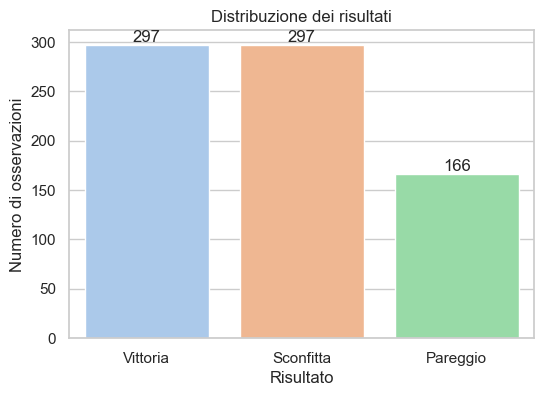

In [33]:
plt.figure(figsize=(6,4))

ax = sns.countplot(
    data=features_df,
    x="result",
    hue="result",
    palette="pastel",
    legend=False
)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom')

plt.title("Distribuzione dei risultati")
plt.xlabel("Risultato")
plt.ylabel("Numero di osservazioni")

plt.show() 

Il grafico mostra che il dataset è leggermente sbilanciato, con un numero minore di pareggi rispetto a vittorie e sconfitte.

Questo risultato è coerente con la natura del calcio, in cui i pareggi si verificano con minore frequenza rispetto agli altri esiti. 

## Numero di tiri e risultato della partita

Viene analizzata la distribuzione del numero totale di tiri nelle diverse classi di risultato.


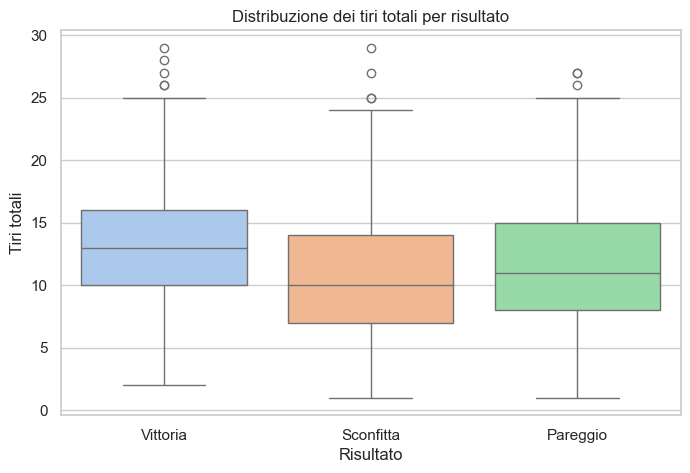

In [34]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=features_df,
    x="result",
    y="total_shots",
    hue="result",
    palette="pastel",
    legend=False
)

plt.title("Distribuzione dei tiri totali per risultato")
plt.xlabel("Risultato")
plt.ylabel("Tiri totali")

plt.show()  

Il grafico evidenzia come le squadre vincenti tendano ad avere una mediana del numero di tiri più elevata rispetto alle squadre sconfitte.

Si osserva inoltre una maggiore variabilità nei valori, ma con una chiara tendenza generale che conferma quanto emerso nell’analisi quantitativa. 

## Tiri in porta e risultato della partita

Viene analizzata la media dei tiri in porta nelle diverse classi di risultato, includendo anche la variabilità (deviazione standard).

Questo tipo di rappresentazione consente di osservare in modo sintetico le differenze tra le prestazioni offensive delle squadre, evidenziando sia il valore medio sia la dispersione dei dati.

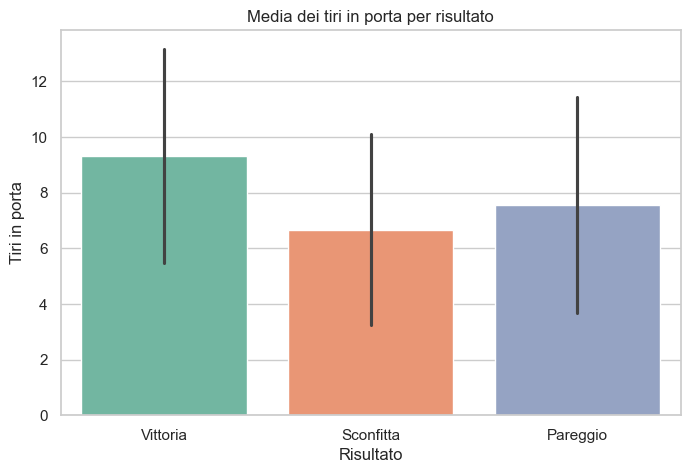

In [35]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=features_df,
    x="result",
    y="shots_on_target",
    estimator="mean",
    errorbar="sd",
    hue="result",          
    palette="Set2",        
    legend=False          
)

plt.title("Media dei tiri in porta per risultato")
plt.xlabel("Risultato")
plt.ylabel("Tiri in porta")

plt.show()   

Si nota che le squadre vincenti tendono ad avere una media di tiri in porta più elevata rispetto a quelle sconfitte, confermando l'importanza dell'efficacia offensiva nel determinare il risultato finale.

## Passaggi e risultato della partita

Viene analizzata la media del numero di passaggi effettuati dalle squadre nelle diverse classi di risultato.

Questo grafico consente di osservare se il volume di gioco, espresso attraverso il numero di passaggi, sia correlato all’esito finale della partita.

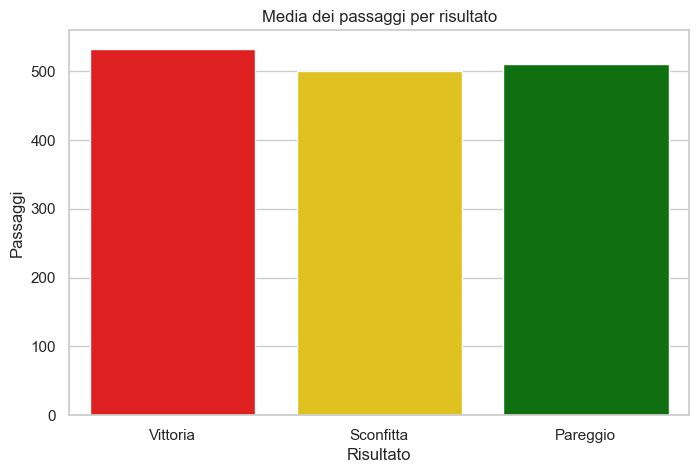

In [36]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=features_df,
    x="result",
    y="Pass",
    estimator="mean",
    errorbar=None,   
    hue="result",
    palette=["red", "gold", "green"],
    legend=False
)

plt.title("Media dei passaggi per risultato")
plt.xlabel("Risultato")
plt.ylabel("Passaggi")

plt.show() 

Dall’analisi emerge che le differenze tra le medie dei passaggi nelle tre classi (vittoria, pareggio, sconfitta) sono relativamente contenute.

In particolare, le squadre vincenti tendono ad avere un numero medio di passaggi leggermente superiore, ma la differenza rispetto alle altre classi non è marcata.

Questo suggerisce che il possesso palla e il volume di gioco non sono di per sé sufficienti a determinare il risultato finale, ma devono essere accompagnati da una maggiore efficacia offensiva.  

## Matrice di correlazione

Viene calcolata la matrice di correlazione tra le principali feature numeriche del dataset.

Questo consente di individuare eventuali relazioni lineari tra le variabili e di comprendere meglio la struttura dei dati.

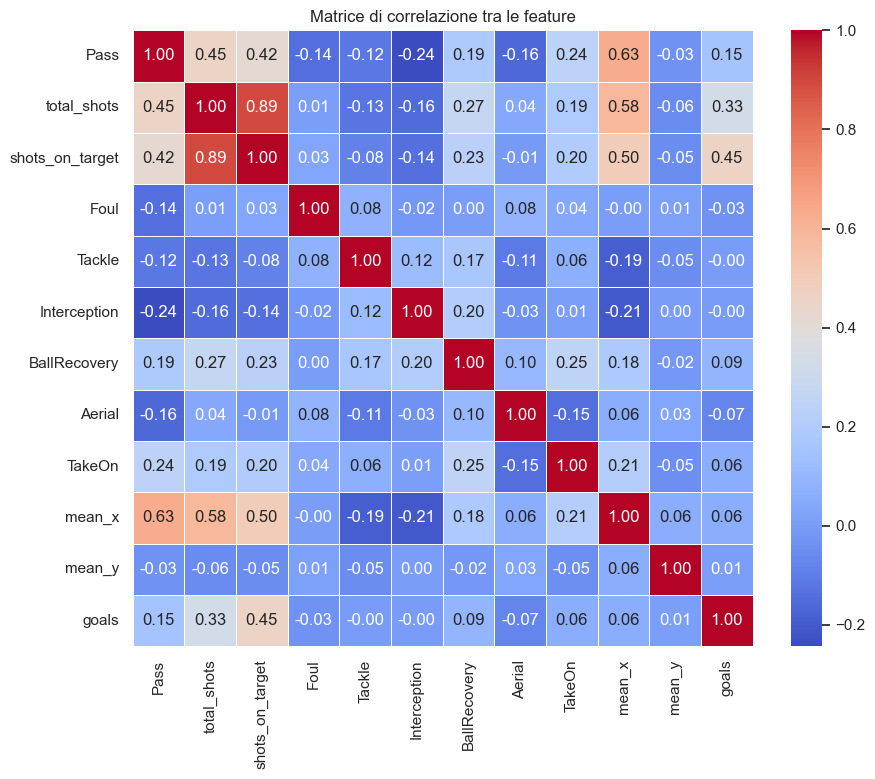

In [37]:
plt.figure(figsize=(10,8))

corr = features_df[feature_numeriche + ["goals"]].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Matrice di correlazione tra le feature")

plt.show() 

Dall’analisi della matrice di correlazione emergono alcune relazioni interessanti tra le feature.

In particolare, si osserva una forte correlazione tra il numero totale di tiri e i tiri in porta, indicando che queste variabili sono strettamente legate tra loro.

Inoltre, i tiri in porta mostrano una correlazione positiva con il numero di goal, confermando il loro ruolo centrale nella determinazione del risultato della partita.

Al contrario, molte feature difensive (come falli, contrasti e intercettazioni) presentano correlazioni deboli o trascurabili con le altre variabili, suggerendo un impatto meno diretto sul risultato finale.

## Relazione tra tiri in porta e goal segnati


Per approfondire l’analisi offensiva, viene studiata la relazione tra il numero di tiri in porta e il numero di goal segnati.

Questo grafico consente di osservare se, in media, a un aumento dei tiri in porta corrisponde un aumento dei goal realizzati. 

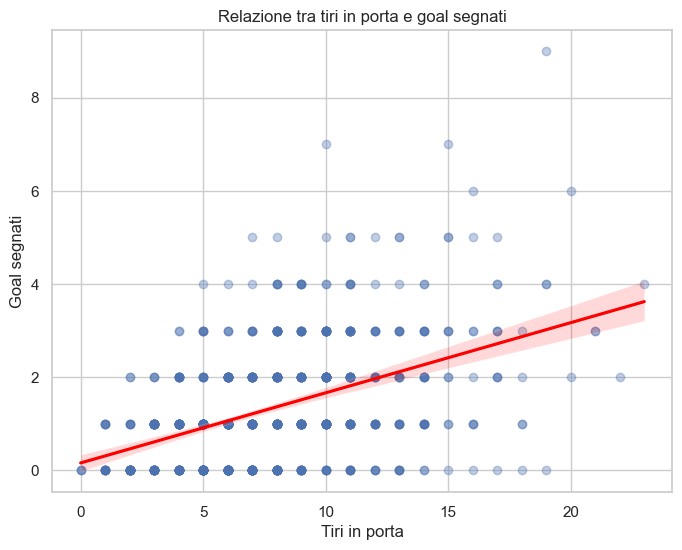

In [38]:
plt.figure(figsize=(8,6))

sns.regplot(
    data=features_df,
    x="shots_on_target",
    y="goals",
    scatter_kws={"alpha": 0.35},
    line_kws={"color": "red"}
)

plt.title("Relazione tra tiri in porta e goal segnati")
plt.xlabel("Tiri in porta")
plt.ylabel("Goal segnati")

plt.show() 

Dal grafico emerge una relazione positiva tra il numero di tiri in porta e il numero di goal segnati.

In media, le squadre che effettuano un numero maggiore di tiri in porta tendono anche a realizzare più goal, confermando il ruolo centrale dell’efficacia offensiva.  

## Ricostruzione del risultato della partita

A partire dai goal corretti precedentemente calcolati, viene ricostruito il risultato di ciascuna squadra in ogni partita.

Il risultato viene espresso nelle tre classi:
- Vittoria
- Pareggio
- Sconfitta 

In [39]:
# =========================
# RISULTATO PARTITA CORRETTO
# =========================

results = []

for match_id in features_df["match_id"].unique():
    match_rows = features_df[features_df["match_id"] == match_id][["team_name", "goals"]].reset_index(drop=True)

    if len(match_rows) != 2:
        continue

    team_a = match_rows.loc[0, "team_name"]
    goals_a = match_rows.loc[0, "goals"]

    team_b = match_rows.loc[1, "team_name"]
    goals_b = match_rows.loc[1, "goals"]

    if goals_a > goals_b:
        results.append({"match_id": match_id, "team_name": team_a, "result": "Vittoria"})
        results.append({"match_id": match_id, "team_name": team_b, "result": "Sconfitta"})
    elif goals_a < goals_b:
        results.append({"match_id": match_id, "team_name": team_a, "result": "Sconfitta"})
        results.append({"match_id": match_id, "team_name": team_b, "result": "Vittoria"})
    else:
        results.append({"match_id": match_id, "team_name": team_a, "result": "Pareggio"})
        results.append({"match_id": match_id, "team_name": team_b, "result": "Pareggio"})

results_df = pd.DataFrame(results)

features_df = features_df.drop(columns=["result", "result_x", "result_y"], errors="ignore")

features_df = features_df.merge(
    results_df,
    on=["match_id", "team_name"],
    how="left"
)

features_df[["match_id", "team_name", "goals", "result"]].head(10)      

,match_id,team_name,goals,result
0,1,Manchester United,1,Vittoria
1,1,Burnley,0,Sconfitta
2,2,Aston Villa,0,Sconfitta
3,2,Manchester City,2,Vittoria
4,3,Southampton,0,Sconfitta
5,3,Crystal Palace,1,Vittoria
6,4,Arsenal,3,Vittoria
7,4,Fulham,0,Sconfitta
8,5,Liverpool,4,Vittoria
9,5,Leeds United,3,Sconfitta


## Goal subiti e punti

Per ciascuna squadra vengono poi calcolati:
- i goal subiti, ottenuti come differenza tra i goal totali della partita e i goal segnati dalla squadra;
- i punti ottenuti, assegnando 3 punti per la vittoria, 1 per il pareggio e 0 per la sconfitta. 

In [40]:
# =========================
# GOAL SUBITI E PUNTI
# =========================

features_df["goals_conceded"] = (
    features_df.groupby("match_id")["goals"].transform("sum") - features_df["goals"]
)

features_df["points"] = features_df["result"].map({
    "Vittoria": 3,
    "Pareggio": 1,
    "Sconfitta": 0
})

features_df[["match_id", "team_name", "goals", "goals_conceded", "result", "points"]].head(10)

,match_id,team_name,goals,goals_conceded,result,points
0,1,Manchester United,1,0,Vittoria,3
1,1,Burnley,0,1,Sconfitta,0
2,2,Aston Villa,0,2,Sconfitta,0
3,2,Manchester City,2,0,Vittoria,3
4,3,Southampton,0,1,Sconfitta,0
5,3,Crystal Palace,1,0,Vittoria,3
6,4,Arsenal,3,0,Vittoria,3
7,4,Fulham,0,3,Sconfitta,0
8,5,Liverpool,4,3,Vittoria,3
9,5,Leeds United,3,4,Sconfitta,0


## Classifica finale del campionato

Infine, le statistiche partita per partita vengono aggregate a livello di squadra per ottenere la classifica finale del campionato.

Per ogni squadra vengono calcolati:
- punti totali;
- partite giocate;
- vittorie, pareggi e sconfitte;
- goal segnati;
- goal subiti;
- differenza reti.  

In [41]:
# =========================
# CLASSIFICA FINALE
# =========================

classifica = (
    features_df.groupby("team_name")
    .agg(
        points=("points", "sum"),
        played=("match_id", "nunique"),
        wins=("result", lambda x: (x == "Vittoria").sum()),
        draws=("result", lambda x: (x == "Pareggio").sum()),
        losses=("result", lambda x: (x == "Sconfitta").sum()),
        goals=("goals", "sum"),
        goals_conceded=("goals_conceded", "sum")
    )
    .reset_index()
)

classifica["goal_difference"] = classifica["goals"] - classifica["goals_conceded"]

classifica = classifica.sort_values(
    by=["points", "goal_difference", "goals"],
    ascending=False
).reset_index(drop=True)

classifica  

,team_name,points,played,wins,draws,losses,goals,goals_conceded,goal_difference
0,Manchester City,86,38,27,5,6,83,32,51
1,Manchester United,74,38,21,11,6,73,44,29
2,Liverpool,69,38,20,9,9,68,42,26
3,Chelsea,67,38,19,10,9,58,36,22
4,Leicester City,66,38,20,6,12,68,50,18
5,West Ham United,65,38,19,8,11,62,47,15
6,Tottenham Hotspur,62,38,18,8,12,68,45,23
7,Arsenal,61,38,18,7,13,55,39,16
8,Leeds United,59,38,18,5,15,62,54,8
9,Everton,59,38,17,8,13,47,48,-1


In [42]:
# =========================
# CONTROLLI DI COERENZA
# =========================

# Ogni squadra deve avere 38 partite
classifica[["team_name", "played"]] 

,team_name,played
0,Manchester City,38
1,Manchester United,38
2,Liverpool,38
3,Chelsea,38
4,Leicester City,38
5,West Ham United,38
6,Tottenham Hotspur,38
7,Arsenal,38
8,Leeds United,38
9,Everton,38


In [43]:
# Distribuzione risultati complessiva
features_df["result"].value_counts() 

result
Vittoria     297
Sconfitta    297
Pareggio     166
Name: count, dtype: int64

In [44]:
# Top 10 classifica
classifica.head(10) 

,team_name,points,played,wins,draws,losses,goals,goals_conceded,goal_difference
0,Manchester City,86,38,27,5,6,83,32,51
1,Manchester United,74,38,21,11,6,73,44,29
2,Liverpool,69,38,20,9,9,68,42,26
3,Chelsea,67,38,19,10,9,58,36,22
4,Leicester City,66,38,20,6,12,68,50,18
5,West Ham United,65,38,19,8,11,62,47,15
6,Tottenham Hotspur,62,38,18,8,12,68,45,23
7,Arsenal,61,38,18,7,13,55,39,16
8,Leeds United,59,38,18,5,15,62,54,8
9,Everton,59,38,17,8,13,47,48,-1


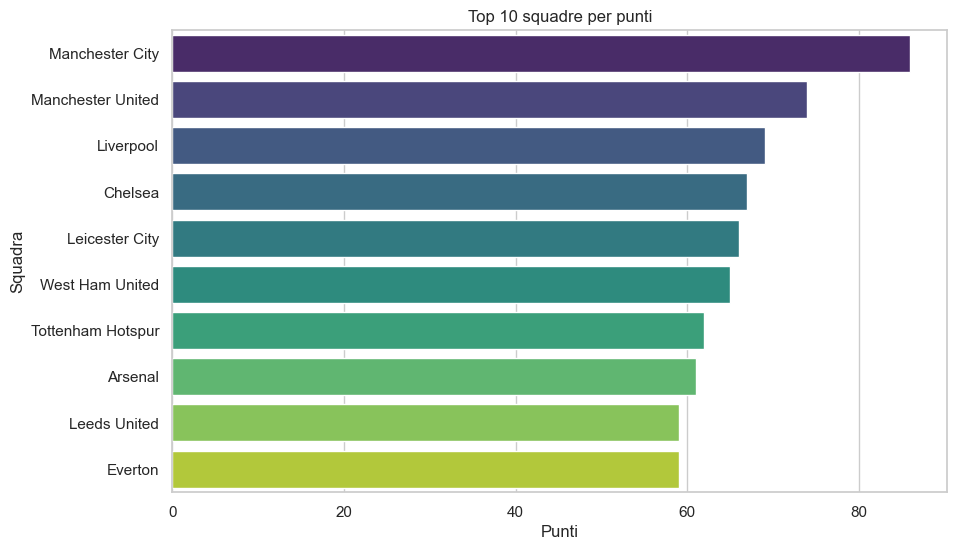

In [45]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=classifica.head(10),
    x="points",
    y="team_name",
    hue="team_name",
    palette="viridis",
    legend=False
)

plt.title("Top 10 squadre per punti")
plt.xlabel("Punti")
plt.ylabel("Squadra")

plt.show()  

Dal grafico emerge chiaramente la gerarchia tra le squadre nella stagione analizzata.

Le squadre nelle prime posizioni mostrano un numero significativamente più alto di punti, indicando una maggiore costanza di rendimento nel corso del campionato.

Questa rappresentazione fornisce una sintesi efficace delle performance complessive delle squadre.  

## Differenza reti e punti in classifica

Viene analizzata la relazione tra la differenza reti e i punti ottenuti in classifica.

Questo grafico consente di verificare quanto la capacità di segnare più goal rispetto agli avversari influenzi il posizionamento finale in campionato.  

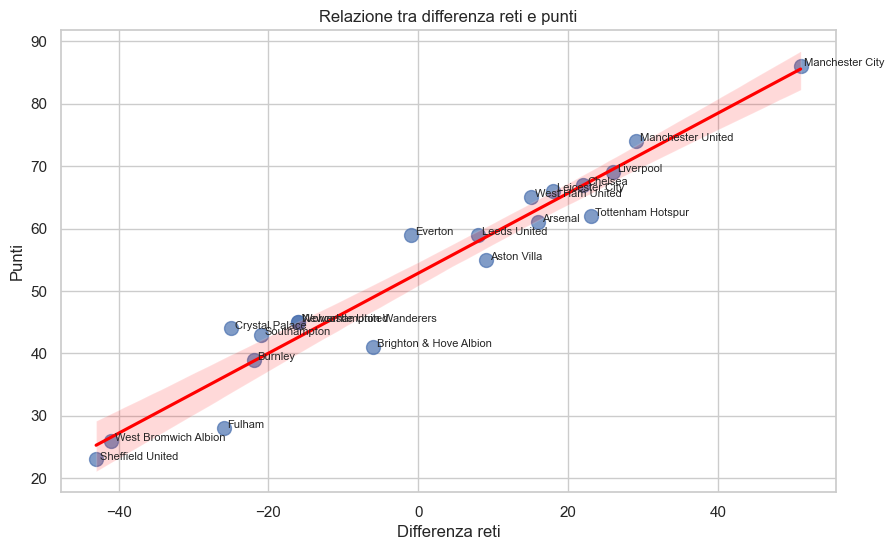

In [46]:
plt.figure(figsize=(10,6))

sns.regplot(
    data=classifica,
    x="goal_difference",
    y="points",
    scatter_kws={"s": 100, "alpha": 0.7},
    line_kws={"color": "red"}
)

# Aggiungiamo le etichette delle squadre
for i in range(len(classifica)):
    plt.text(
        classifica["goal_difference"][i] + 0.5,
        classifica["points"][i],
        classifica["team_name"][i],
        fontsize=8
    )

plt.title("Relazione tra differenza reti e punti")
plt.xlabel("Differenza reti")
plt.ylabel("Punti")

plt.show() 

Dal grafico emerge una relazione positiva tra differenza reti e punti.

Le squadre con una differenza reti più elevata tendono ad ottenere un numero maggiore di punti, confermando che l’equilibrio tra fase offensiva e difensiva è determinante per il successo nel campionato.  

## Distribuzione dei goal segnati e subiti

Per analizzare il comportamento complessivo delle squadre, viene rappresentata la distribuzione congiunta dei goal segnati e dei goal subiti.

A differenza di un semplice scatter plot, viene utilizzata una stima di densità per evidenziare le aree in cui si concentrano maggiormente le squadre, permettendo una lettura più sintetica del fenomeno.  

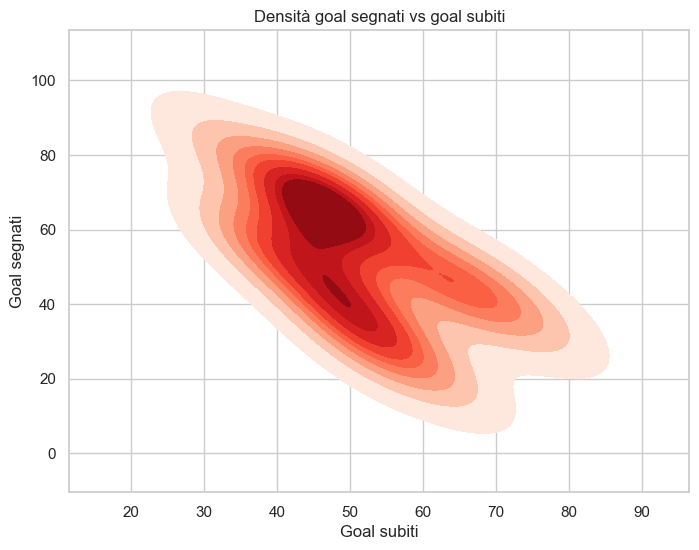

In [47]:
plt.figure(figsize=(8,6))

sns.kdeplot(
    data=classifica,
    x="goals_conceded",
    y="goals",
    fill=True,
    cmap="Reds",
    thresh=0.05
)

plt.title("Densità goal segnati vs goal subiti")
plt.xlabel("Goal subiti")
plt.ylabel("Goal segnati")

plt.show()   

Dal grafico emerge che la maggior parte delle squadre si concentra in una zona intermedia, caratterizzata da valori simili di goal segnati e subiti.

Si osserva inoltre una tendenza inversa: all’aumentare dei goal subiti tende a diminuire il numero di goal segnati.

Le squadre più performanti si collocano nella parte superiore sinistra del grafico (molti goal segnati e pochi subiti), mentre le squadre meno competitive si trovano nella zona opposta.  

## Analisi delle prestazioni individuali: i migliori marcatori


Dopo aver analizzato il comportamento generale delle squadre, ci focalizziamo ora sulle performance individuali dei giocatori.

In particolare, analizziamo i marcatori più prolifici del campionato, al fine di individuare i giocatori che hanno avuto il maggiore impatto offensivo nella stagione.

Questa analisi è utile non solo a livello descrittivo, ma anche in ottica predittiva: le performance offensive individuali possono infatti contribuire in modo significativo al risultato finale delle partite e quindi essere rilevanti nella fase successiva di classificazione. 

In [48]:
# =========================
# TOP MARCATORI
# =========================

# Estrazione goal dai dati eventi
goals_players = df[df["isGoal"] == True]

top_scorers = (
    goals_players
    .groupby(["name", "team_name"])
    .size()
    .reset_index(name="goals")
    .sort_values("goals", ascending=False)
)
# =========================
# TABELLA TOP 20 
# =========================

top20 = top_scorers.head(20)

top20_display = top20[["name", "team_name", "goals"]].copy()
top20_display.columns = ["Giocatore", "Squadra", "Goal"]

# Reset index e numerazione da 1 a 20
top20_display = top20_display.reset_index(drop=True)
top20_display.index = top20_display.index + 1

top20_display  

,Giocatore,Squadra,Goal
1,Harry Kane,Tottenham Hotspur,23
2,Mohamed Salah,Liverpool,22
3,Bruno Fernandes,Manchester United,18
4,Patrick Bamford,Leeds United,17
5,Son Heung-Min,Tottenham Hotspur,17
6,Dominic Calvert-Lewin,Everton,16
7,Jamie Vardy,Leicester City,15
8,Ollie Watkins,Aston Villa,14
9,Ilkay Gündogan,Manchester City,13
10,Alexandre Lacazette,Arsenal,13


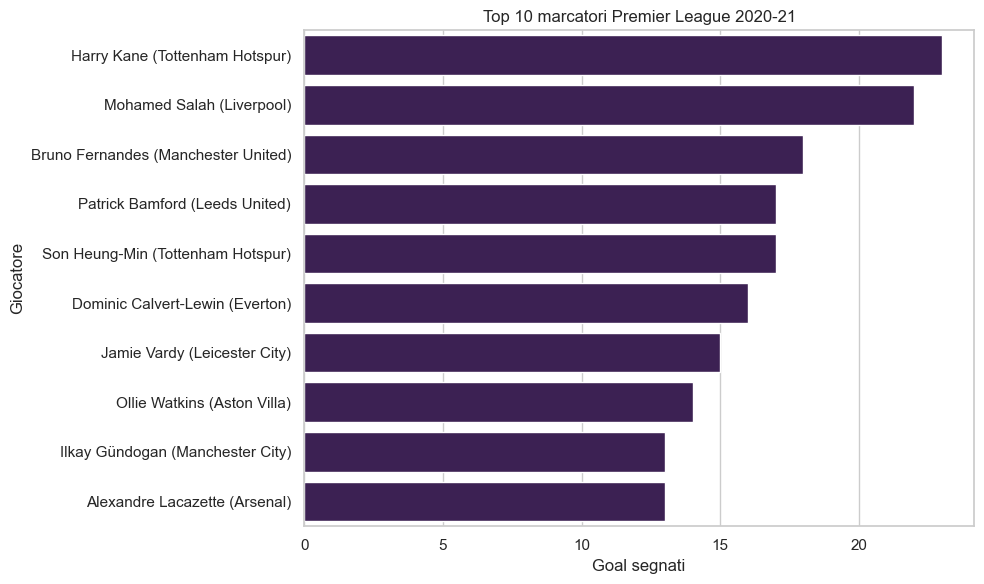

In [49]:
# =========================
# GRAFICO TOP 10
# =========================

top10 = top_scorers.head(10).copy()

# Etichetta più leggibile
top10["player_team"] = top10["name"] + " (" + top10["team_name"] + ")"

plt.figure(figsize=(10,6))

sns.barplot(
    data=top10,
    x="goals",
    y="player_team",
    color="#3D195B"   
)

plt.title("Top 10 marcatori Premier League 2020-21")
plt.xlabel("Goal segnati")
plt.ylabel("Giocatore")

plt.tight_layout()
plt.show()




Dall’analisi dei migliori marcatori emerge un aspetto particolarmente interessante: la presenza di un giocatore altamente prolifico non garantisce necessariamente il successo complessivo della squadra.

Ad esempio, il miglior marcatore della stagione è Harry Kane (Tottenham Hotspur), mentre il Tottenham non figura tra le prime 5 posizioni della classifica finale. Allo stesso modo, osservando la top 20 dei marcatori, si nota come la squadra vincitrice del campionato (Manchester City) sia rappresentata da un numero limitato di giocatori nelle prime posizioni.

Questo suggerisce che il successo di una squadra non dipende esclusivamente dalla presenza di un singolo giocatore in grado di segnare molti gol, ma piuttosto da una distribuzione più equilibrata delle reti tra più giocatori.

Le squadre più performanti tendono infatti a presentare un gioco più collettivo, in cui il contributo offensivo è condiviso tra diversi elementi della rosa, rendendo l’attacco meno prevedibile e più efficace nel lungo periodo.

Questo fenomeno è coerente anche con l’evoluzione recente del calcio, in cui risulta sempre più raro osservare singoli giocatori con numeri estremamente elevati di gol stagionali, a favore di una maggiore organizzazione e distribuzione del gioco offensivo.

In conclusione, l’analisi evidenzia come le performance individuali siano certamente rilevanti, ma non sufficienti da sole a determinare il successo complessivo di una squadra. 

### Analisi delle prestazioni individuali: gli assist

Dopo aver analizzato i migliori marcatori, l’attenzione si sposta sulle prestazioni individuali legate alla creazione delle azioni offensive.

In particolare, si intende individuare i giocatori che hanno fornito il maggior numero di assist durante la stagione, ovvero coloro che hanno contribuito direttamente alla realizzazione dei goal.

Poiché il dataset non presenta una variabile esplicita relativa agli assist, è stato necessario individuare un possibile indicatore indiretto. Dall’analisi preliminare, si è osservato che il campo relatedPlayerId, associato agli eventi di goal, potrebbe rappresentare il giocatore autore dell’ultimo passaggio prima della rete.

L’obiettivo di questa sezione è quindi:
- verificare questa ipotesi,
- costruire una classifica degli assist,
- analizzare i risultati ottenuti.  

In [50]:
# =========================
# ESTRAZIONE ASSIST
# =========================

# prendiamo solo i goal con relatedPlayerId valorizzato
assists_df = df[
    (df["isGoal"] == True) &
    (df["relatedPlayerId"].notna())
][["relatedPlayerId"]].copy()

# lookup per ottenere nome e squadra
player_lookup = df[["playerId", "name", "team_name"]].drop_duplicates()

assists_df = assists_df.merge(
    player_lookup,
    left_on="relatedPlayerId",
    right_on="playerId",
    how="left"
)

# conteggio assist per giocatore
top_assists = assists_df.groupby(["name", "team_name"]).size().reset_index(name="Assist")

# ordinamento
top_assists = top_assists.sort_values(by="Assist", ascending=False)

# reset index pulito
top_assists = top_assists.reset_index(drop=True)

# visualizzazione top 20
top_assists.head(20)  

,name,team_name,Assist
0,Harry Kane,Tottenham Hotspur,14
1,Kevin De Bruyne,Manchester City,12
2,Bruno Fernandes,Manchester United,12
3,Son Heung-Min,Tottenham Hotspur,10
4,Jack Grealish,Aston Villa,10
5,Marcus Rashford,Manchester United,9
6,Jamie Vardy,Leicester City,9
7,Raphinha,Leeds United,9
8,Pascal Groß,Brighton & Hove Albion,8
9,Aaron Cresswell,West Ham United,8


Per verificare la correttezza dell’interpretazione del campo relatedPlayerId, i risultati ottenuti sono stati confrontati con le statistiche ufficiali della stagione di Premier League 2020-2021.

Il confronto evidenzia una corrispondenza perfetta tra i giocatori identificati come migliori assistman e quelli presenti nelle classifiche ufficiali. In particolare, i principali giocatori (come Harry Kane, Kevin De Bruyne e Bruno Fernandes) risultano perfettamente allineati sia per posizione che per numero di assist.

Questa coerenza conferma che il campo relatedPlayerId può essere considerato un indicatore affidabile per identificare gli assist all’interno del dataset. 

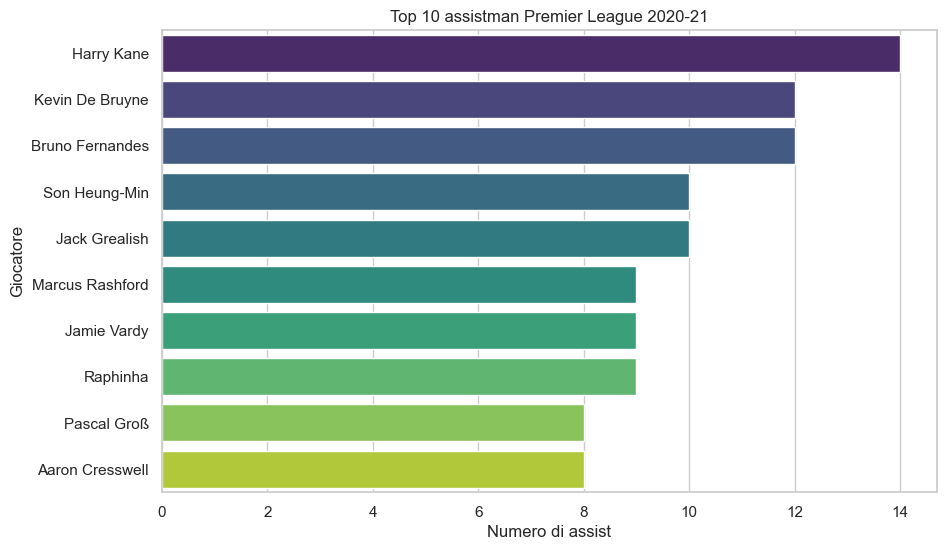

In [51]:
# =========================
# GRAFICO TOP ASSIST
# =========================

top10_assists = top_assists.head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    data=top10_assists,
    x="Assist",
    y="name",
    hue="name",
    palette="viridis",
    legend=False
)

plt.title("Top 10 assistman Premier League 2020-21")
plt.xlabel("Numero di assist")
plt.ylabel("Giocatore")

plt.show()  

Dall’analisi emerge che i giocatori con il maggior numero di assist appartengono prevalentemente a squadre di alto livello e ricoprono ruoli offensivi o di centrocampo avanzato.

È interessante osservare come alcuni giocatori, come Harry Kane, risultino ai vertici sia nella classifica dei marcatori sia in quella degli assist, evidenziando un contributo offensivo estremamente completo.

Allo stesso tempo, la presenza di diversi giocatori con un numero simile di assist suggerisce che molte squadre distribuiscono la creazione delle occasioni tra più elementi, piuttosto che dipendere da un unico playmaker.

Questo conferma l’importanza del gioco di squadra nella costruzione delle azioni offensive e mette in evidenza come le prestazioni individuali siano spesso il risultato di dinamiche collettive.

In conclusione, l’analisi dimostra che, anche in assenza di una variabile esplicita, è possibile derivare informazioni significative attraverso un’interpretazione accurata dei dati e una successiva validazione esterna. 

## Giocatori con il maggior numero di passaggi

Dopo aver analizzato le principali prestazioni offensive individuali, l’attenzione viene ora spostata su una dimensione diversa ma altrettanto importante del gioco: la costruzione della manovra.

In particolare, vengono analizzati i giocatori che hanno effettuato il maggior numero di passaggi nel corso della stagione, così da individuare i principali riferimenti nella gestione del possesso e nello sviluppo del gioco delle rispettive squadre.

Questa analisi consente di evidenziare i calciatori maggiormente coinvolti nella circolazione del pallone e nella fase di impostazione, offrendo informazioni utili anche per comprendere meglio lo stile di gioco delle squadre.  

In [52]:
# =========================
# TOP PASSAGGI  
# =========================

passes_players = df[df["type_displayName"] == "Pass"]

top_passers = (
    passes_players
    .groupby(["name", "team_name"])
    .size()
    .reset_index(name="Passaggi")
    .sort_values("Passaggi", ascending=False)
    .reset_index(drop=True)
)

top20_passers = top_passers.head(20).copy()
top20_passers.columns = ["Giocatore", "Squadra", "Passaggi"]

top20_passers.index = top20_passers.index + 1

top20_passers 

,Giocatore,Squadra,Passaggi
1,Andrew Robertson,Liverpool,3295
2,Trent Alexander-Arnold,Liverpool,3004
3,Rodri,Manchester City,2800
4,Pierre-Emile Højbjerg,Tottenham Hotspur,2778
5,Luke Ayling,Leeds United,2762
6,Rúben Dias,Manchester City,2717
7,James Ward-Prowse,Southampton,2703
8,Youri Tielemans,Leicester City,2630
9,Bruno Fernandes,Manchester United,2318
10,Harry Maguire,Manchester United,2243


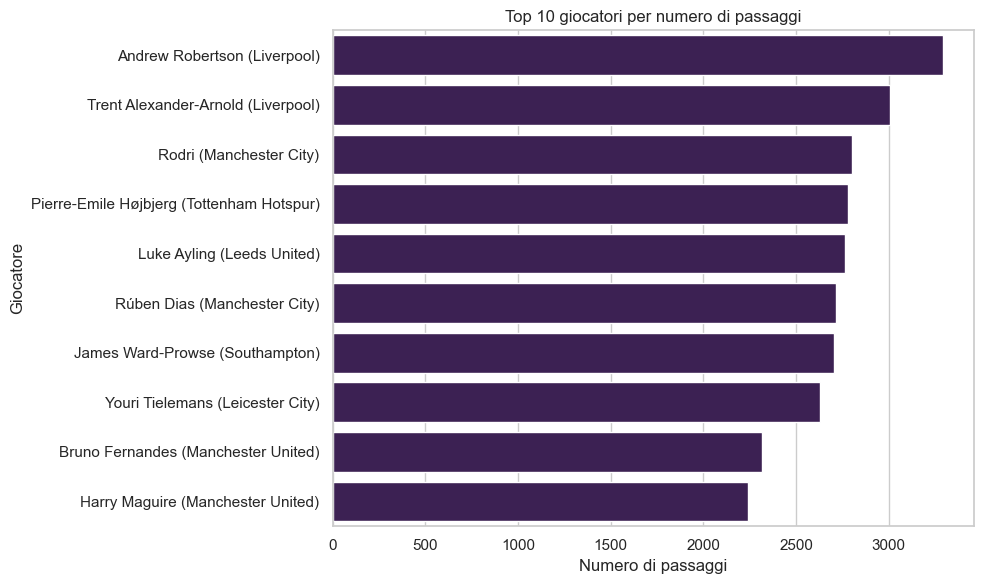

In [53]:
# =========================
# GRAFICO 
# =========================

top10_passers = top_passers.head(10).copy()
top10_passers["player_team"] = top10_passers["name"] + " (" + top10_passers["team_name"] + ")"

plt.figure(figsize=(10,6))

sns.barplot(
    data=top10_passers,
    x="Passaggi",
    y="player_team",
    color="#3D195B"
)

plt.title("Top 10 giocatori per numero di passaggi")
plt.xlabel("Numero di passaggi")
plt.ylabel("Giocatore")

plt.tight_layout()
plt.show()  

Dall’analisi dei giocatori con il maggior numero di passaggi emerge che le prime posizioni sono occupate prevalentemente da difensori e centrocampisti centrali.

Questo risultato è coerente con il ruolo di questi giocatori all’interno della squadra, in quanto sono maggiormente coinvolti nella fase di costruzione del gioco e nella gestione del possesso palla.

Confrontando questa classifica con quella degli assist, si osserva una differenza significativa: i giocatori con più assist sono generalmente calciatori offensivi, mentre quelli con più passaggi operano in zone più arretrate del campo.

Questo evidenzia come il numero di passaggi non sia direttamente correlato alla produzione di assist, ma rappresenti piuttosto un indicatore del coinvolgimento complessivo nel gioco.

In particolare, i difensori e i centrocampisti tendono a effettuare un elevato numero di passaggi per mantenere il possesso e costruire l’azione, mentre gli assist sono maggiormente associati a giocatori in grado di creare occasioni negli ultimi metri.

In conclusione, questa analisi permette di distinguere tra quantità di gioco (numero di passaggi) e qualità offensiva (assist), fornendo una visione più completa delle prestazioni individuali.  

## Analisi delle prestazioni offensive: i tiri

Dopo aver analizzato i goal, gli assist e il numero di passaggi, l’attenzione si sposta ora su un’altra componente fondamentale della fase offensiva: i tiri.

L’obiettivo di questa sezione è individuare i giocatori che hanno concluso di più verso la porta nel corso della stagione, così da evidenziare i calciatori maggiormente coinvolti nella finalizzazione delle azioni.

Prima di costruire la classifica, è necessario interpretare correttamente il dataset. Infatti, tra i tipi di evento non compare una categoria generica chiamata Shot, ma i tiri risultano suddivisi in più classi specifiche:
- MissedShots, cioè tiri non andati a segno;
- SavedShot, cioè tiri parati dal portiere;
- ShotOnPost, cioè tiri terminati sul palo o sulla traversa;
- Goal, che rappresenta invece i tiri conclusi con una rete.

Per ottenere il numero totale di tiri effettuati da ciascun giocatore, è quindi necessario considerare congiuntamente tutti questi eventi.

Questa analisi è particolarmente utile perché consente non solo di identificare i giocatori più attivi in zona offensiva, ma anche di confrontare successivamente il numero di tiri con i goal realizzati, ottenendo così indicazioni sull’efficienza realizzativa.  

In [54]:
# =========================
# VERIFICA EVENTI DI TIRO NEL DATASET
# =========================

[c for c in df["type_displayName"].unique() if "shot" in c.lower()]

['MissedShots', 'SavedShot', 'ShotOnPost']

In [55]:
# =========================
# TOP TIRATORI
# =========================

# I tiri totali vengono ricostruiti sommando:
# - MissedShots
# - SavedShot
# - ShotOnPost
# - Goal
shots_events = df[
    df["type_displayName"].isin([
        "MissedShots",
        "SavedShot",
        "ShotOnPost",
        "Goal"
    ])
].copy()

top_shooters = (
    shots_events
    .groupby(["name", "team_name"])
    .size()
    .reset_index(name="Tiri")
    .sort_values("Tiri", ascending=False)
    .reset_index(drop=True)
)

top20_shooters = top_shooters.head(20).copy()
top20_shooters.columns = ["Giocatore", "Squadra", "Tiri"]

top20_shooters.index = top20_shooters.index + 1

top20_shooters 

,Giocatore,Squadra,Tiri
1,Harry Kane,Tottenham Hotspur,137
2,Mohamed Salah,Liverpool,126
3,Bruno Fernandes,Manchester United,121
4,Patrick Bamford,Leeds United,107
5,Ollie Watkins,Aston Villa,97
6,Sadio Mané,Liverpool,94
7,Roberto Firmino,Liverpool,83
8,Dominic Calvert-Lewin,Everton,83
9,Jamie Vardy,Leicester City,82
10,Mason Mount,Chelsea,82


La tabella seguente riporta i 20 giocatori con il maggior numero di tiri complessivi nella stagione, mentre il grafico rappresenta in modo sintetico i primi 10.

In questo caso, il numero di tiri è stato ottenuto considerando sia i tiri terminati senza goal sia quelli conclusi con una rete, così da rappresentare correttamente il volume offensivo di ciascun giocatore. 

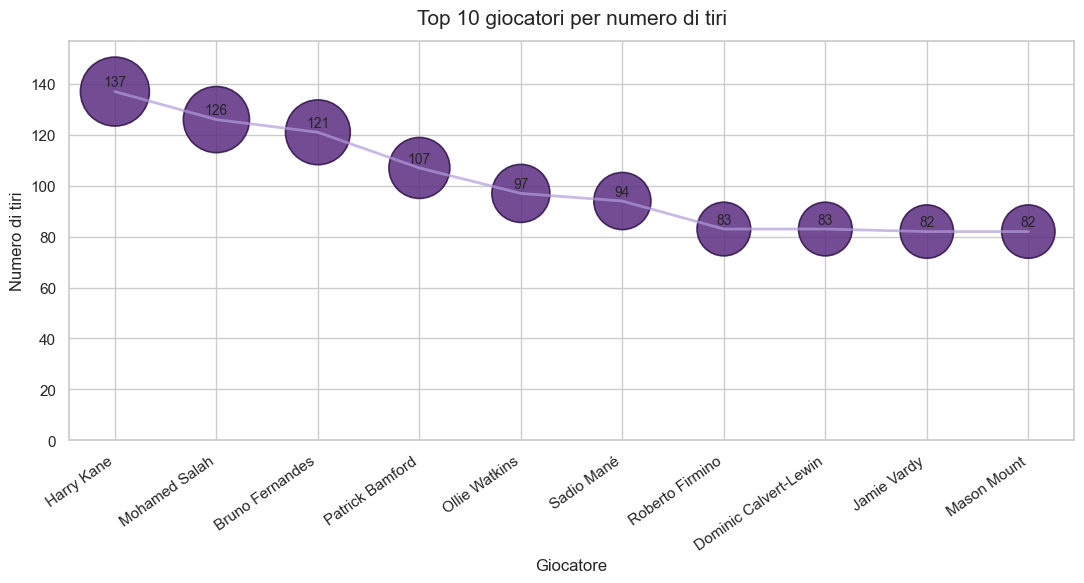

In [56]:
# =========================
# GRAFICO TOP 10 TIRATORI
# VERSIONE BUBBLE CHART
# =========================

top10_shooters = top_shooters.head(10).copy().reset_index(drop=True)

sns.set_style("whitegrid")
plt.figure(figsize=(11,6))

x_labels = top10_shooters["name"]
y_values = top10_shooters["Tiri"]

# dimensione cerchi proporzionale ai tiri
sizes = y_values * 18

plt.scatter(
    x=range(len(top10_shooters)),
    y=y_values,
    s=sizes,
    color="#5A2D82",
    edgecolors="#2E1248",
    linewidths=1.2,
    alpha=0.85
)

# linea leggera per rendere il grafico più compatto e leggibile
plt.plot(
    range(len(top10_shooters)),
    y_values,
    color="#B39DDB",
    linewidth=2,
    alpha=0.7
)

plt.xticks(
    range(len(top10_shooters)),
    x_labels,
    rotation=35,
    ha="right"
)

plt.title("Top 10 giocatori per numero di tiri", fontsize=15, pad=12)
plt.xlabel("Giocatore")
plt.ylabel("Numero di tiri")

# valori sopra i cerchi
for i, v in enumerate(y_values):
    plt.text(i, v + 2, str(v), ha="center", fontsize=10)

plt.ylim(0, max(y_values)+20)

plt.tight_layout()
plt.show()  

Dall’analisi dei giocatori con il maggior numero di tiri emerge chiaramente come i calciatori più presenti in questa classifica siano prevalentemente attaccanti o giocatori offensivi.

In particolare, Harry Kane e Mohamed Salah risultano i giocatori con il maggior numero di conclusioni, confermando il loro ruolo centrale nelle rispettive squadre in termini di finalizzazione delle azioni offensive. Allo stesso modo, la presenza di Bruno Fernandes evidenzia come anche alcuni centrocampisti offensivi possano contribuire significativamente al numero di tiri.

Un aspetto interessante riguarda il confronto con le analisi precedenti sui goal e sugli assist. Infatti, i giocatori che effettuano più tiri non coincidono sempre perfettamente con quelli che segnano di più o forniscono più assist. Questo suggerisce che un alto numero di conclusioni rappresenta principalmente una misura del volume offensivo, ma non necessariamente dell’efficacia.

Ad esempio, alcuni giocatori presenti nella classifica dei tiri potrebbero avere una bassa percentuale realizzativa, mentre altri, pur tirando meno, risultano più efficienti sotto porta. Questo evidenzia la differenza tra:
- capacità di arrivare alla conclusione;
- capacità di trasformare le occasioni in goal.

Inoltre, confrontando questa analisi con quella sui passaggi e sugli assist, si osserva come i giocatori più coinvolti nella costruzione del gioco (ad esempio centrocampisti) tendano a comparire meno tra i primi per numero di tiri, ma risultino fondamentali nella creazione delle occasioni.

In conclusione, il numero di tiri rappresenta una metrica fondamentale per valutare la presenza offensiva dei giocatori, ma deve essere sempre interpretato insieme ad altre variabili, come goal e assist, per ottenere una visione più completa delle prestazioni individuali. Questa integrazione di informazioni sarà particolarmente utile nelle fasi successive del progetto, in cui tali feature verranno utilizzate per la classificazione dei risultati delle partite.  

## Efficienza realizzativa dei principali tiratori

Dopo aver analizzato il numero complessivo di tiri effettuati dai giocatori, è utile valutare anche quanto queste conclusioni risultino efficaci.

A questo scopo, viene introdotto un indicatore di efficienza realizzativa, definito come il rapporto tra goal segnati e tiri effettuati.

L’efficienza viene espressa in percentuale, così da rendere più immediato il confronto tra giocatori.

Per evitare che il confronto risulti distorto da calciatori con un numero troppo basso di conclusioni, l’analisi viene limitata ai giocatori che hanno effettuato almeno 50 tiri nel corso della stagione.

In questo modo, l’indicatore risulta più stabile e rappresentativo dell’effettiva capacità realizzativa.



In [57]:
# =========================
# EFFICIENZA REALIZZATIVA
# =========================

# Goal per giocatore
goals_players = (
    df[df["type_displayName"] == "Goal"]
    .groupby(["name", "team_name"])
    .size()
    .reset_index(name="Goal")
)

# Tiri per giocatore
shots_events = df[
    df["type_displayName"].isin([
        "MissedShots",
        "SavedShot",
        "ShotOnPost",
        "Goal"
    ])
].copy()

shots_players = (
    shots_events
    .groupby(["name", "team_name"])
    .size()
    .reset_index(name="Tiri")
)

# Merge
efficiency_df = shots_players.merge(
    goals_players,
    on=["name", "team_name"],
    how="left"
)

efficiency_df["Goal"] = efficiency_df["Goal"].fillna(0).astype(int)

# Efficienza
efficiency_df["Efficienza"] = efficiency_df["Goal"] / efficiency_df["Tiri"]

# Filtro minimo tiri
efficiency_df = efficiency_df[efficiency_df["Tiri"] >= 50].copy()

# Percentuale
efficiency_df["Efficienza %"] = (efficiency_df["Efficienza"] * 100).round(2)

# Ordinamento
efficiency_df = efficiency_df.sort_values(
    by="Efficienza",
    ascending=False
).reset_index(drop=True)

# Tabella finale
top20_efficiency = efficiency_df.head(20).copy()

top20_efficiency = top20_efficiency[[
    "name", "team_name", "Tiri", "Goal", "Efficienza %"
]].copy()

top20_efficiency.columns = ["Giocatore", "Squadra", "Tiri", "Goal", "Efficienza %"]

top20_efficiency.index = top20_efficiency.index + 1

top20_efficiency 

,Giocatore,Squadra,Tiri,Goal,Efficienza %
1,Son Heung-Min,Tottenham Hotspur,68,17,25.00
2,Ilkay Gündogan,Manchester City,54,13,24.07
3,Danny Ings,Southampton,57,12,21.05
4,Kelechi Iheanacho,Leicester City,59,12,20.34
5,Dominic Calvert-Lewin,Everton,83,16,19.28
6,Pierre-Emerick Aubameyang,Arsenal,58,11,18.97
7,Wilfried Zaha,Crystal Palace,60,11,18.33
8,Jamie Vardy,Leicester City,82,15,18.29
9,Mohamed Salah,Liverpool,126,22,17.46
10,Chris Wood,Burnley,70,12,17.14


La tabella seguente riporta i 20 giocatori con la migliore efficienza realizzativa tra quelli che hanno effettuato almeno 50 tiri.

Il grafico mostra i primi 15, evidenziando i giocatori più efficaci nella trasformazione delle conclusioni in goal.  

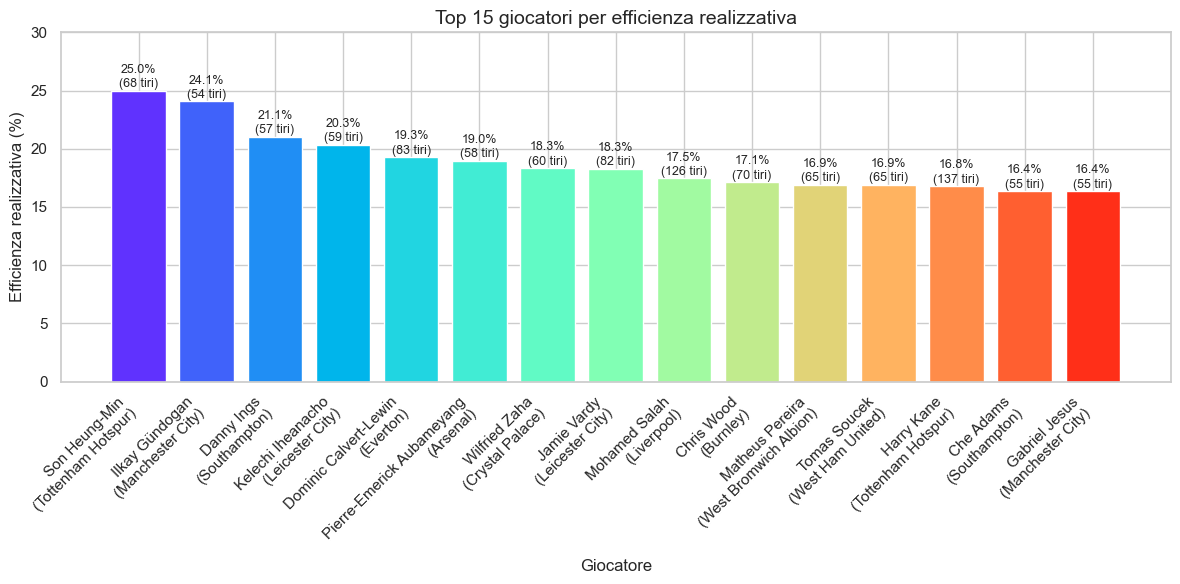

In [58]:
# =========================
# GRAFICO EFFICIENZA (TOP 15) - VERSIONE MIGLIORATA
# =========================

top15_eff = efficiency_df.head(15).copy()
top15_eff["player_team"] = top15_eff["name"] + "\n(" + top15_eff["team_name"] + ")"

sns.set_style("whitegrid")
plt.figure(figsize=(12,6))

colors = sns.color_palette("rainbow", len(top15_eff))

plt.bar(
    top15_eff["player_team"],
    top15_eff["Efficienza %"],
    color=colors
)

plt.title("Top 15 giocatori per efficienza realizzativa", fontsize=14)
plt.xlabel("Giocatore")
plt.ylabel("Efficienza realizzativa (%)")

plt.xticks(rotation=45, ha="right")

for i, (eff, tiri) in enumerate(zip(top15_eff["Efficienza %"], top15_eff["Tiri"])):
    plt.text(i, eff + 0.3, f"{eff:.1f}%\n({tiri} tiri)", ha="center", fontsize=9)

plt.ylim(0, top15_eff["Efficienza %"].max() + 5)

plt.tight_layout()
plt.show()   

Dall’analisi emerge come i giocatori con la maggiore efficienza realizzativa non siano necessariamente quelli con il maggior numero di tiri o di goal.

Un caso emblematico è quello di Harry Kane, capocannoniere della stagione, che pur avendo realizzato 23 goal su ben 137 tiri non compare tra i primi per efficienza. Questo evidenzia come un elevato volume di conclusioni non garantisca automaticamente una maggiore precisione sotto porta.

Al contrario, giocatori come Son Heung-Min mostrano una maggiore capacità di conversione delle occasioni, risultando più “cinici” a parità o con un numero inferiore di tiri.

Questo conferma che l’efficienza rappresenta una metrica complementare rispetto al numero di tiri, utile per valutare la qualità delle conclusioni oltre alla loro quantità.

Tali informazioni risultano particolarmente rilevanti anche in ottica predittiva, poiché permettono di distinguere tra volume offensivo ed efficacia realizzativa.

## Analisi degli autogol

Un ulteriore aspetto interessante riguarda gli autogol, ossia quelle situazioni in cui una squadra subisce una rete a causa di una propria giocata involontaria.

Poiché nella fase precedente i goal sono già stati corretti tenendo conto degli eventi di autorete, questa analisi ha finalità principalmente descrittiva e permette di evidenziare i giocatori maggiormente coinvolti in tali episodi.

Data la natura relativamente rara di questo evento, si riporta una tabella riassuntiva dei 10 giocatori con il maggior numero di autogol nel corso della stagione. 

In [59]:
# =========================
# AUTOGOAL
# =========================

own_goals_df = df[df["isOwnGoal"] == True].copy()

top_own_goals = (
    own_goals_df
    .groupby(["name", "team_name"])
    .size()
    .reset_index(name="Autogol")
    .sort_values(by="Autogol", ascending=False)
    .reset_index(drop=True)
)

top_own_goals_display = top_own_goals.copy()
top_own_goals_display.columns = ["Giocatore", "Squadra", "Autogol"]
top_own_goals_display.index = top_own_goals_display.index + 1

top_own_goals_display.head(10)

,Giocatore,Squadra,Autogol
1,Craig Dawson,West Ham United,2
2,Antonio Rüdiger,Chelsea,1
3,Raúl Jiménez,Wolverhampton Wanderers,1
4,Leander Dendoncker,Wolverhampton Wanderers,1
5,Lewis Dunk,Brighton & Hove Albion,1
6,Luke Shaw,Manchester United,1
7,Matt Ritchie,Newcastle United,1
8,Nélson Semedo,Wolverhampton Wanderers,1
9,Phil Jagielka,Sheffield United,1
10,Pierre-Emerick Aubameyang,Arsenal,1


Dalla tabella emerge come gli autogol rappresentino eventi relativamente rari e distribuiti su un numero limitato di giocatori.

A differenza di altre metriche offensive o difensive, gli autogol non costituiscono una caratteristica strutturale del comportamento di una squadra, ma piuttosto episodi occasionali e spesso non sistematici.

Per questo motivo, pur essendo un’informazione interessante dal punto di vista descrittivo, il loro peso interpretativo risulta più contenuto rispetto ad altre variabili analizzate in precedenza.

## Analisi disciplinare: cartellini gialli e rossi

Per completare l’analisi delle prestazioni individuali, è utile considerare anche l’aspetto disciplinare, osservando il numero di cartellini ricevuti dai giocatori.

In particolare, vengono distinti i cartellini gialli e rossi, in quanto rappresentano livelli diversi di gravità delle infrazioni e permettono di analizzare il comportamento in campo in termini di aggressività e rischio.

Questa analisi consente di individuare i giocatori maggiormente coinvolti in situazioni di fallo e di valutare eventuali pattern nel comportamento disciplinare. 

In [60]:
# =========================
# CARTELLINI
# =========================

cards_df = df[df["cardType_displayName"].notna()].copy()

# GIALLI
yellow_cards = (
    cards_df[cards_df["cardType_displayName"] == "Yellow"]
    .groupby(["name", "team_name"])
    .size()
    .reset_index(name="Gialli")
    .sort_values(by="Gialli", ascending=False)
)

# ROSSI
red_cards = (
    cards_df[cards_df["cardType_displayName"].isin(["Red","SecondYellow"])]
    .groupby(["name", "team_name"])
    .size()
    .reset_index(name="Rossi")
    .sort_values(by="Rossi", ascending=False)
)

# Display pulito
yellow_display = yellow_cards.head(20).copy()
yellow_display.columns = ["Giocatore", "Squadra", "Cartellini Gialli"]
yellow_display.index = yellow_display.index + 1

red_display = red_cards.head(15).copy()
red_display.columns = ["Giocatore", "Squadra", "Cartellini Rossi"]
red_display.index = red_display.index + 1
yellow_display  

,Giocatore,Squadra,Cartellini Gialli
172,John McGinn,Aston Villa,12
125,Harry Maguire,Manchester United,11
63,Conor Gallagher,West Bromwich Albion,11
186,Kalvin Phillips,Leeds United,10
290,Pierre-Emile Højbjerg,Tottenham Hotspur,9
225,Mason Holgate,Everton,9
87,Douglas Luiz,Aston Villa,9
214,Luke Shaw,Manchester United,8
127,Héctor Bellerín,Arsenal,8
171,John Lundstram,Sheffield United,8


In [61]:
red_display

,Giocatore,Squadra,Cartellini Rossi
29,Lewis Dunk,Brighton & Hove Albion,2
1,Aboubakar Kamara,Fulham,1
36,Neal Maupay,Brighton & Hove Albion,1
27,João Moutinho,Wolverhampton Wanderers,1
28,Kieran Gibbs,West Bromwich Albion,1
30,Liam Cooper,Leeds United,1
31,Lucas Digne,Everton,1
32,Luka Milivojevic,Crystal Palace,1
33,Matheus Pereira,West Bromwich Albion,1
34,Matt Doherty,Tottenham Hotspur,1


L’analisi dei cartellini evidenzia come il comportamento disciplinare vari significativamente tra i giocatori.

I cartellini gialli risultano più frequenti e riflettono uno stile di gioco più aggressivo o un maggiore coinvolgimento in fase difensiva.

I cartellini rossi, invece, sono eventi più rari ma con un impatto rilevante sull’andamento della partita, in quanto comportano l’espulsione del giocatore.

Nel complesso, questi indicatori permettono di arricchire la valutazione delle prestazioni individuali introducendo una componente comportamentale, utile anche per interpretare il rendimento delle squadre. 

## Analisi difensiva: tackle, intercetti e clearance

Per completare l’analisi delle prestazioni individuali, vengono considerate alcune tra le principali variabili difensive presenti nel dataset.

In particolare, l’attenzione è posta su:
- i tackle riusciti, che rappresentano i contrasti diretti con l’avversario;
- le intercettazioni, che misurano la capacità di leggere il gioco e anticipare le linee di passaggio;
- le clearance, cioè i rinvii difensivi effettuati per allontanare il pericolo.

Poiché queste azioni descrivono aspetti diversi della fase difensiva, vengono analizzate separatamente.

In [62]:
# =========================
# TACKLE RIUSCITI
# =========================

tackles = df[
    (df["type_displayName"] == "Tackle") &
    (df["outcomeType_displayName"] == "Successful")
]

tackles_players = (
    tackles.groupby(["name", "team_name"])
    .size()
    .reset_index(name="Tackle riusciti")
    .sort_values(by="Tackle riusciti", ascending=False)
)

tackles_display = tackles_players.head(10).copy()
tackles_display.columns = ["Giocatore", "Squadra", "Tackle riusciti"]
tackles_display.index = tackles_display.index + 1

tackles_display 

,Giocatore,Squadra,Tackle riusciti
447,Yves Bissouma,Brighton & Hove Albion,68
437,Wilfred Ndidi,Leicester City,63
271,Luke Ayling,Leeds United,61
4,Aaron Wan-Bissaka,Manchester United,54
262,Kyle Walker-Peters,Southampton,53
357,Pierre-Emile Højbjerg,Tottenham Hotspur,51
198,James Ward-Prowse,Southampton,49
330,Nélson Semedo,Wolverhampton Wanderers,48
383,Rúben Neves,Wolverhampton Wanderers,46
267,Liam Cooper,Leeds United,45


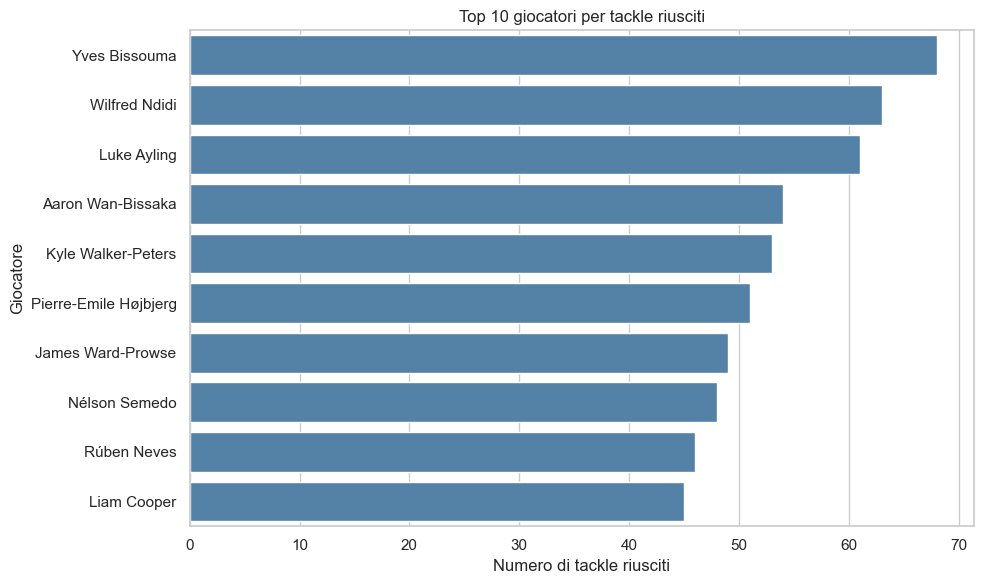

In [63]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=tackles_players.head(10),
    x="Tackle riusciti",
    y="name",
    color="steelblue"
)

plt.title("Top 10 giocatori per tackle riusciti")
plt.xlabel("Numero di tackle riusciti")
plt.ylabel("Giocatore")

plt.tight_layout()
plt.show() 

In [64]:
# =========================
# INTERCETTI
# =========================

interceptions = df[df["type_displayName"] == "Interception"]

interceptions_players = (
    interceptions.groupby(["name", "team_name"])
    .size()
    .reset_index(name="Intercetti")
    .sort_values(by="Intercetti", ascending=False)
)

interceptions_display = interceptions_players.head(10).copy()
interceptions_display.columns = ["Giocatore", "Squadra", "Intercetti"]
interceptions_display.index = interceptions_display.index + 1

interceptions_display 

,Giocatore,Squadra,Intercetti
191,Jan Bednarek,Southampton,84
225,Josh Brownhill,Burnley,69
371,Rúben Neves,Wolverhampton Wanderers,65
435,Yves Bissouma,Brighton & Hove Albion,64
3,Aaron Wan-Bissaka,Manchester United,62
50,Ben White,Brighton & Hove Albion,62
412,Tomas Soucek,West Ham United,62
257,Liam Cooper,Leeds United,61
425,Wilfred Ndidi,Leicester City,61
424,Wesley Fofana,Leicester City,61


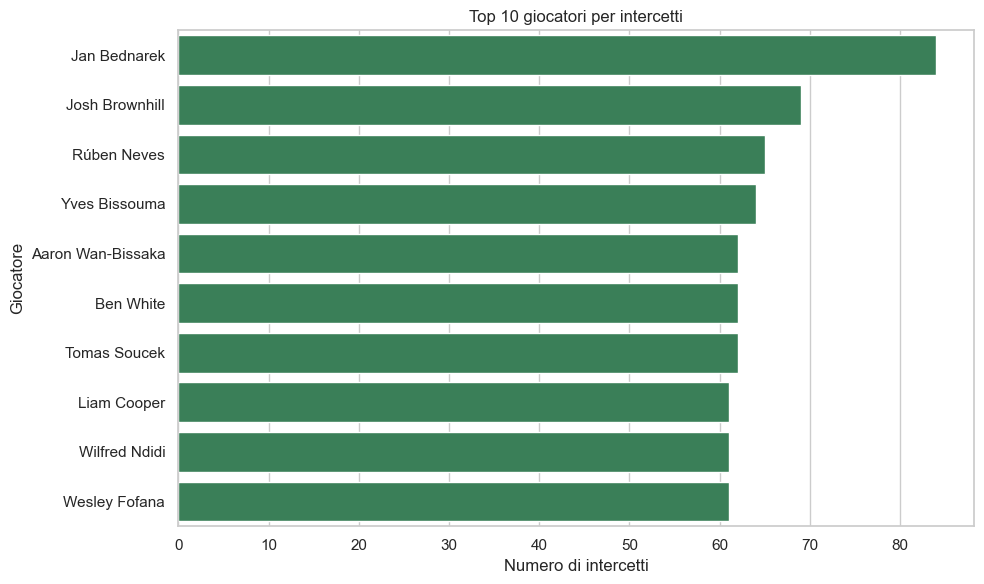

In [65]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=interceptions_players.head(10),
    x="Intercetti",
    y="name",
    color="seagreen"
)

plt.title("Top 10 giocatori per intercetti")
plt.xlabel("Numero di intercetti")
plt.ylabel("Giocatore")

plt.tight_layout()
plt.show() 

In [66]:
# =========================
# CLEARANCE
# =========================

clearances = df[df["type_displayName"] == "Clearance"]

clearances_players = (
    clearances.groupby(["name", "team_name"])
    .size()
    .reset_index(name="Clearance")
    .sort_values(by="Clearance", ascending=False)
)

clearances_display = clearances_players.head(10).copy()
clearances_display.columns = ["Giocatore", "Squadra", "Clearance"]
clearances_display.index = clearances_display.index + 1

clearances_display 

,Giocatore,Squadra,Clearance
438,Tosin Adarabioyo,Fulham,197
443,Tyrone Mings,Aston Villa,172
201,James Tarkowski,Burnley,163
138,Ezri Konsa Ngoyo,Aston Villa,162
315,Michael Keane,Everton,161
267,Kyle Bartley,West Bromwich Albion,159
218,Joachim Andersen,Fulham,151
52,Ben Mee,Burnley,148
144,Federico Fernández,Newcastle United,147
84,Conor Coady,Wolverhampton Wanderers,134


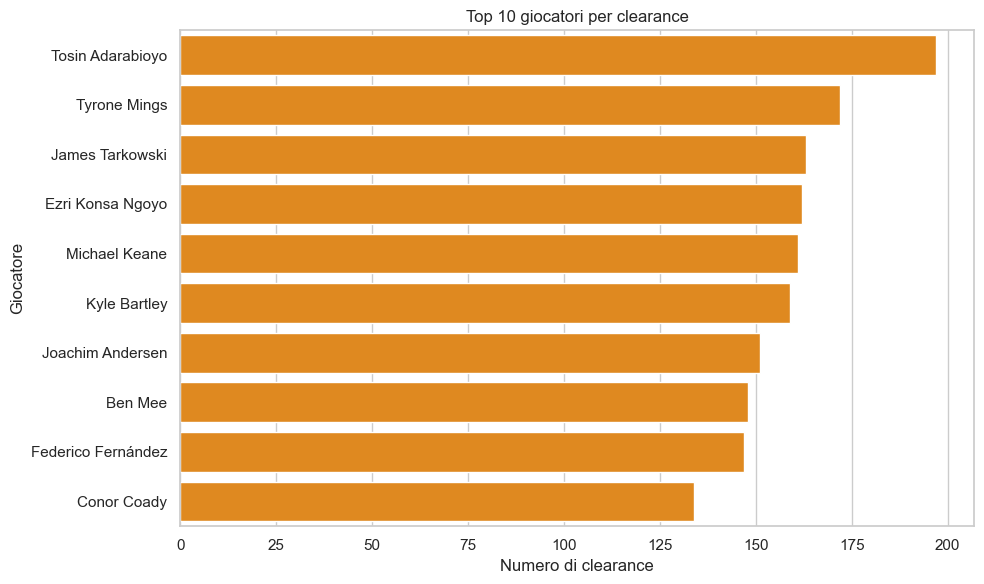

In [67]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=clearances_players.head(10),
    x="Clearance",
    y="name",
    color="darkorange"
)

plt.title("Top 10 giocatori per clearance")
plt.xlabel("Numero di clearance")
plt.ylabel("Giocatore")

plt.tight_layout()
plt.show() 

L’analisi separata delle principali metriche difensive evidenzia come i diversi indicatori descrivano aspetti differenti del comportamento in fase di non possesso.

I tackle riusciti mettono in luce i giocatori più coinvolti nei contrasti diretti, gli intercetti evidenziano invece la capacità di leggere il gioco e anticipare le azioni avversarie, mentre le clearance risultano più tipiche di giocatori chiamati a liberare l’area nelle situazioni di pressione difensiva.

Questa distinzione è importante, poiché un giocatore può eccellere in una di queste dimensioni senza necessariamente primeggiare nelle altre.

Nel complesso, tali metriche permettono di arricchire l’analisi delle prestazioni individuali, introducendo una componente difensiva complementare rispetto alle variabili offensive considerate in precedenza.

## Identificazione dei migliori difensori

Dopo aver analizzato separatamente le principali metriche difensive, è possibile costruire un indicatore sintetico che consenta di confrontare i giocatori in modo più completo.

Poiché le diverse statistiche (tackle, intercetti e clearance) descrivono aspetti complementari della fase difensiva, viene definito un indice difensivo totale come somma di queste tre componenti.

Questo indicatore non rappresenta una misura assoluta della qualità difensiva, ma fornisce una stima complessiva del contributo dei giocatori nelle azioni di non possesso. 

In [68]:
# =========================
# INDICE DIFENSIVO
# =========================

# Merge delle 3 tabelle
defensive_index = tackles_players.merge(
    interceptions_players,
    on=["name", "team_name"],
    how="outer"
).merge(
    clearances_players,
    on=["name", "team_name"],
    how="outer"
).fillna(0)

# Conversione interi
for col in ["Tackle riusciti", "Intercetti", "Clearance"]:
    defensive_index[col] = defensive_index[col].astype(int)

# Indice totale
defensive_index["Indice difensivo"] = (
    defensive_index["Tackle riusciti"] +
    defensive_index["Intercetti"] +
    defensive_index["Clearance"]
)

# Ordinamento
defensive_index = defensive_index.sort_values(
    by="Indice difensivo",
    ascending=False
)

# Top 10
top_defenders = defensive_index.head(20).copy()
top_defenders.columns = ["Giocatore", "Squadra", "Tackle", "Intercetti", "Clearance", "Indice difensivo"]
top_defenders.index = top_defenders.index + 1

top_defenders 

,Giocatore,Squadra,Tackle,Intercetti,Clearance,Indice difensivo
461,Tosin Adarabioyo,Fulham,19,42,197,258
212,James Tarkowski,Burnley,39,44,163,246
217,Jan Bednarek,Southampton,19,84,132,235
466,Tyrone Mings,Aston Villa,16,41,172,229
330,Michael Keane,Everton,15,51,161,227
230,Joachim Andersen,Fulham,19,44,151,214
280,Kyle Bartley,West Bromwich Albion,16,38,159,213
460,Tomas Soucek,West Ham United,41,62,107,210
55,Ben Mee,Burnley,15,43,148,206
147,Ezri Konsa Ngoyo,Aston Villa,13,29,162,204


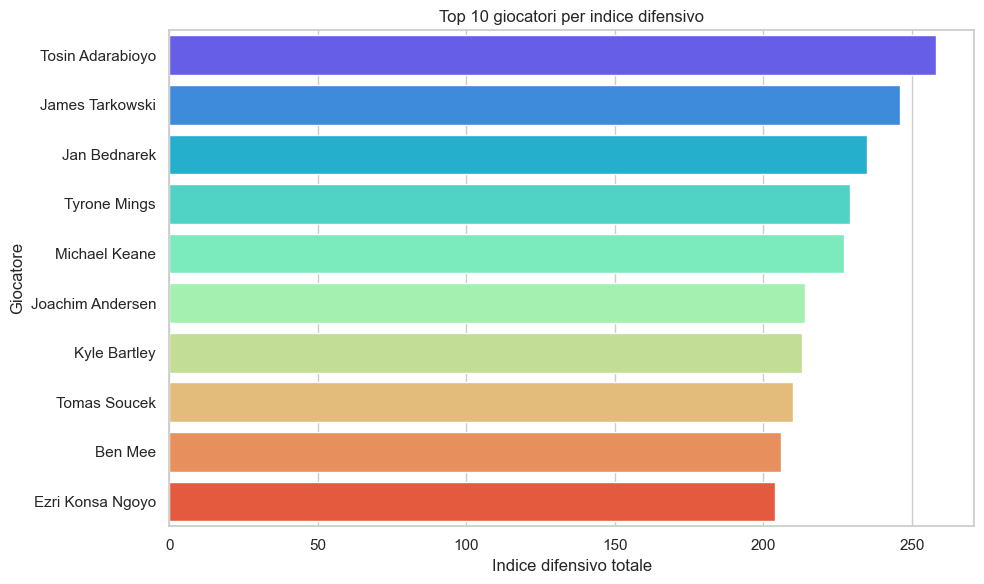

In [69]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=defensive_index.head(10),
    x="Indice difensivo",
    y="name",
    hue="name",
    palette="rainbow"
)

plt.title("Top 10 giocatori per indice difensivo")
plt.xlabel("Indice difensivo totale")
plt.ylabel("Giocatore")

plt.tight_layout()
plt.show() 


Dalla tabella e dal grafico emerge come i giocatori con il valore più elevato dell’indice siano generalmente difensori centrali, caratterizzati da un alto numero di clearance e intercetti.

È interessante notare come alcuni giocatori appartenenti a squadre meno performanti (ad esempio Fulham o Burnley) risultino ai primi posti: questo è dovuto al fatto che tali squadre difendono più frequentemente, aumentando il numero di interventi difensivi.

Pertanto, l’indice difensivo non misura necessariamente la “qualità assoluta” del difensore, ma piuttosto il suo coinvolgimento e impatto nelle azioni difensive durante la stagione.  

## Analisi dei portieri: numero di parate

Prima di passare alla fase di classificazione, è utile considerare anche il contributo dei portieri.

Nel dataset sono presenti eventi specifici relativi ai portieri, tra cui le parate (Save), che rappresentano un indicatore diretto del loro coinvolgimento in fase difensiva.

In questa sezione viene quindi costruita una classifica dei portieri con il maggior numero di parate effettuate nel corso della stagione.

È importante sottolineare che un elevato numero di parate non indica necessariamente una maggiore qualità assoluta del portiere, ma può riflettere anche una maggiore pressione difensiva subita dalla squadra.  

In [70]:
# =====================================
# CLASSIFICA PORTIERI PER NUMERO DI PARATE
# =====================================

gk_saves_players = (
    df[
        (df["type_displayName"] == "Save") &
        (df["position"] == "GK")
    ]
    .groupby(["name", "team_name"])
    .size()
    .reset_index(name="Parate")
    .sort_values(by="Parate", ascending=False)
    .reset_index(drop=True)
)

top_gk_display = gk_saves_players.head(10).copy()
top_gk_display.columns = ["Portiere", "Squadra", "Parate"]
top_gk_display.index = top_gk_display.index + 1

top_gk_display 

,Portiere,Squadra,Parate
1,Sam Johnstone,West Bromwich Albion,166
2,Aaron Ramsdale,Sheffield United,147
3,Emiliano Martínez,Aston Villa,143
4,Illan Meslier,Leeds United,141
5,Alphonse Areola,Fulham,116
6,Nick Pope,Burnley,116
7,Hugo Lloris,Tottenham Hotspur,114
8,Vicente Guaita,Crystal Palace,106
9,Lukasz Fabianski,West Ham United,104
10,Rui Patrício,Wolverhampton Wanderers,101


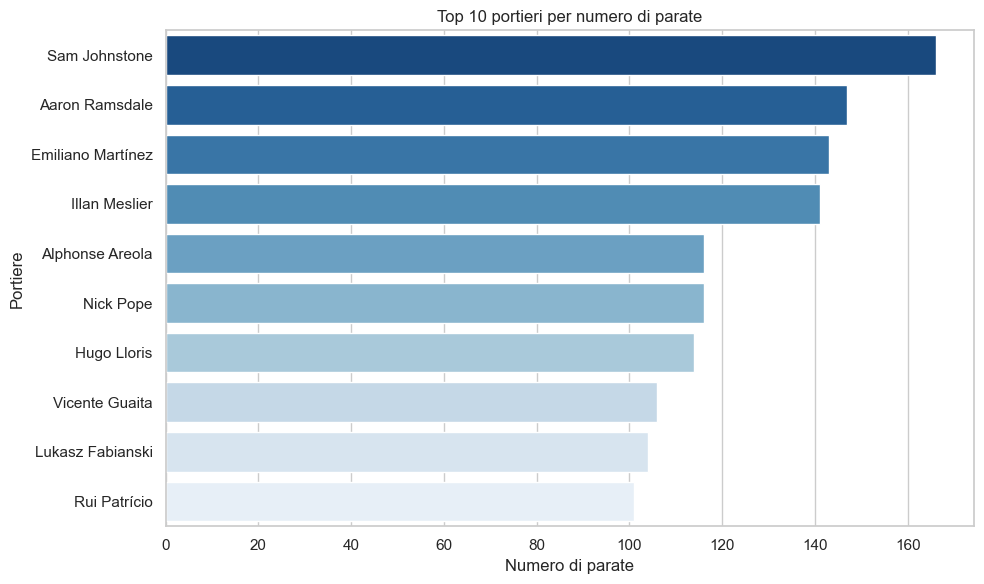

In [71]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=gk_saves_players.head(10),
    x="Parate",
    y="name",
    hue="name",
    palette="Blues_r",
    legend=False
)

plt.title("Top 10 portieri per numero di parate")
plt.xlabel("Numero di parate")
plt.ylabel("Portiere")

plt.tight_layout()
plt.show() 

Dalla classifica emerge che i portieri con il maggior numero di parate appartengono prevalentemente a squadre che, nel corso della stagione, hanno subito un elevato numero di conclusioni da parte degli avversari.

Ad esempio, portieri come Sam Johnstone (West Bromwich Albion) e Aaron Ramsdale (Sheffield United) occupano le prime posizioni, pur giocando in squadre che hanno avuto difficoltà difensive durante la stagione.

Questo evidenzia come il numero di parate sia fortemente influenzato dal contesto di squadra: un portiere che subisce molti tiri avrà naturalmente più occasioni per effettuare parate.

Di conseguenza, questa metrica misura principalmente il livello di coinvolgimento del portiere nelle azioni difensive, più che la sua qualità assoluta.

Per una valutazione più completa delle prestazioni dei portieri, sarebbe utile integrare ulteriori indicatori, come il numero di clean sheet (partite senza subire gol), il numero di tiri subiti e la percentuale di parate effettuate.

### Clean sheet dei portieri

Per approfondire l’analisi precedente, viene considerato anche il numero di clean sheet, ovvero il numero di partite in cui una squadra non ha subito gol.

Questa metrica fornisce un’indicazione complementare rispetto al numero di parate, in quanto è maggiormente legata alla solidità difensiva complessiva della squadra.

In [72]:
# =====================================
# CLEAN SHEET (SQUADRA)
# =====================================

clean_sheets = (
    features_df[features_df["goals_conceded"] == 0]
    .groupby("team_name")
    .size()
    .reset_index(name="Clean Sheet")
    .sort_values(by="Clean Sheet", ascending=False)
)

clean_sheets

,team_name,Clean Sheet
11,Manchester City,19
4,Chelsea,18
1,Aston Villa,15
12,Manchester United,13
0,Arsenal,12
8,Leeds United,12
16,Tottenham Hotspur,12
10,Liverpool,12
6,Everton,12
2,Brighton & Hove Albion,12


In [73]:
# Portiere principale per squadra (più eventi giocati)
gk_main = (
    df[df["position"] == "GK"]
    .groupby(["team_name", "name"])
    .size()
    .reset_index(name="presenze")
    .sort_values(["team_name", "presenze"], ascending=[True, False])
    .drop_duplicates("team_name")
)

# Merge con clean sheet
clean_sheets_gk = clean_sheets.merge(
    gk_main[["team_name", "name"]],
    on="team_name",
    how="left"
)

clean_sheets_gk.columns = ["Squadra", "Clean Sheet", "Portiere"]

clean_sheets_gk 

,Squadra,Clean Sheet,Portiere
0,Manchester City,19,Ederson
1,Chelsea,18,Édouard Mendy
2,Aston Villa,15,Emiliano Martínez
3,Manchester United,13,David de Gea
4,Arsenal,12,Bernd Leno
5,Leeds United,12,Illan Meslier
6,Tottenham Hotspur,12,Hugo Lloris
7,Liverpool,12,Alisson
8,Everton,12,Jordan Pickford
9,Brighton & Hove Albion,12,Robert Sánchez


L’analisi dei clean sheet consente di integrare quanto osservato in precedenza sul numero di parate.

Dalla tabella emerge chiaramente che le squadre con il maggior numero di clean sheet sono generalmente quelle più solide dal punto di vista difensivo, come Manchester City e Chelsea, che occupano le prime posizioni.

Confrontando questi risultati con la classifica dei portieri per numero di parate, si osserva una differenza significativa: i portieri con più parate (come Sam Johnstone e Aaron Ramsdale) appartengono a squadre che registrano pochi clean sheet.

Questo conferma che un elevato numero di parate è spesso associato a una maggiore pressione difensiva, ovvero a un numero elevato di tiri subiti dalla squadra.

Al contrario, i portieri delle squadre più forti difensivamente tendono a registrare meno parate, ma ottengono un numero maggiore di clean sheet, grazie a una migliore organizzazione difensiva che limita le occasioni avversarie.

In conclusione, le due metriche analizzate risultano complementari: il numero di parate misura il coinvolgimento del portiere nelle azioni difensive, mentre i clean sheet rappresentano un indicatore più diretto della solidità difensiva complessiva della squadra. 

### Numero di parate per squadra

Oltre all’analisi a livello di singolo portiere, è utile considerare il numero di parate effettuate a livello di squadra per ciascuna partita.

Questa informazione rappresenta un indicatore della pressione difensiva subita: un numero elevato di parate suggerisce infatti che la squadra ha concesso molte conclusioni agli avversari.

Pertanto, questa feature può risultare utile anche nella fase di classificazione del risultato della partita. 

In [74]:
# =====================================
# SAVE PER SQUADRA-PARTITA
# =====================================

team_saves = (
    df[df["type_displayName"] == "Save"]
    .groupby(["match_id", "team_name"])
    .size()
    .reset_index(name="Saves")
)

team_saves.head()

,match_id,team_name,Saves
0,1,Burnley,10
1,1,Manchester United,5
2,2,Aston Villa,17
3,2,Manchester City,7
4,3,Crystal Palace,6


La variabile "Saves" rappresenta il numero di parate effettuate da una squadra in una determinata partita.

Questa metrica fornisce un’indicazione indiretta del numero di tiri subiti e, quindi, della pressione offensiva esercitata dagli avversari.

Di conseguenza, essa può contribuire a migliorare la capacità del modello di classificazione nel distinguere tra vittorie, pareggi e sconfitte. 

In [75]:
features_df = features_df.merge(
    team_saves,
    on=["match_id", "team_name"],
    how="left"
)

features_df["Saves"] = features_df["Saves"].fillna(0).astype(int)

### Analisi delle coordinate spaziali

Per arricchire l’analisi, vengono considerate anche le informazioni spaziali presenti nel dataset.

In particolare, a partire dalle coordinate (x, y) associate a ciascun evento di gioco, sono state calcolate le coordinate medie per ogni squadra in ogni partita (mean_x, mean_y), al fine di ottenere una rappresentazione del posizionamento medio in campo.

Successivamente, queste feature vengono analizzate in relazione al risultato della partita (Vittoria, Pareggio, Sconfitta), per verificarne l’eventuale capacità discriminante.

In [76]:
xy_analysis = features_df.groupby("result")[["mean_x", "mean_y"]].mean()
xy_analysis 

,mean_x,mean_y
result,,
Pareggio,45.144963,49.499525
Sconfitta,45.336328,49.357387
Vittoria,45.269974,49.596860


Nel dataset originale, ogni evento è associato a coordinate spaziali (x, y) che rappresentano la posizione sul campo in cui l’azione si è verificata.

A partire da queste informazioni, sono state calcolate per ciascuna squadra e partita le coordinate medie degli eventi (mean_x, mean_y), con l’obiettivo di descrivere il posizionamento medio in campo durante il match.

I risultati ottenuti sono i seguenti:

- Vittoria → mean_x ≈ 45.27, mean_y ≈ 49.60  
- Pareggio → mean_x ≈ 45.14, mean_y ≈ 49.50  
- Sconfitta → mean_x ≈ 45.33, mean_y ≈ 49.36  

Si osserva come i valori medi risultino molto simili tra le diverse classi di risultato.

Questo indica che il posizionamento medio delle azioni in campo non varia significativamente tra squadre vincenti, perdenti o che pareggiano.

Di conseguenza, queste feature non risultano particolarmente discriminanti ai fini della classificazione del risultato della partita, suggerendo che altri fattori (come l’efficacia offensiva o la qualità delle occasioni create) abbiano un impatto maggiore sull’esito finale. 

# Classificazione del risultato della partita

## Introduzione al problema

In questa fase del progetto ci si concentra sulla costruzione di modelli di classificazione in grado di prevedere il risultato finale di una partita di calcio.

Il problema consiste nel classificare ogni partita in una delle seguenti tre categorie:
- Vittoria
- Pareggio
- Sconfitta

Si tratta quindi di un problema di **classificazione multiclass**, in cui l’obiettivo è determinare se le feature costruite a partire dagli eventi di gioco siano sufficientemente informative da distinguere tra i diversi esiti.

Una delle principali difficoltà del problema riguarda il **pareggio**, che rappresenta un risultato meno frequente e più difficile da modellare, in quanto spesso emerge in partite caratterizzate da equilibrio piuttosto che da una chiara superiorità di una squadra.


## Strategia adottata: approccio Two-Stage

Per affrontare il problema è stato scelto un approccio **two-stage (a due stadi)**, che permette di scomporre la classificazione multiclass in due problemi binari più semplici.

### Stadio 1 — Pareggio vs Non Pareggio

Nel primo stadio il modello ha il compito di distinguere tra:
- Pareggio
- Non Pareggio

L’obiettivo è identificare le partite caratterizzate da **equilibrio tra le due squadre**, tipico dei pareggi.



### Stadio 2 — Vittoria vs Sconfitta

Nel secondo stadio, applicato solo ai casi classificati come *Non Pareggio*, il modello distingue tra:
- Vittoria
- Sconfitta

In questa fase l’attenzione si sposta sulla **differenza di prestazione tra le squadre**, cioè su quale delle due abbia mostrato una superiorità tale da determinare il risultato.



### Modello finale

Il modello finale è ottenuto combinando i due stadi:

- Se il primo modello predice **Pareggio**, il risultato finale è Pareggio
- Altrimenti, il secondo modello determina se si tratta di Vittoria o Sconfitta

Questo approccio consente di trattare separatamente:
- le partite equilibrate (pareggi)
- le partite con una chiara direzione (vittoria/sconfitta)


# Scelta delle feature

Prima di addestrare i modelli, è stata effettuata una selezione delle feature in modo da includere esclusivamente variabili che descrivono il comportamento di gioco delle squadre.

Sono state escluse:
- variabili identificative (come match_id, team_name)
- variabili direttamente legate al risultato (come goal, punti, goal subiti)

Queste ultime sono state eliminate per evitare fenomeni di data leakage, in quanto contengono informazioni troppo direttamente correlate al target.

Sono state invece mantenute e costruite feature che descrivono:
- produzione offensiva (tiri, tiri in porta)
- attività difensiva (tackle, clearance)
- gestione del possesso (passaggi)
- presenza territoriale (posizioni medie sul campo)

È stato inoltre effettuato un controllo preliminare sulle feature al fine di verificare l’assenza di valori anomali, variabili costanti e dati mancanti, confermando la qualità e la coerenza delle variabili utilizzate nel modello.

# Feature utilizzate

## Stadio 1 — Pareggio vs Non Pareggio

Le feature utilizzate nel primo modello sono progettate per catturare il grado di equilibrio tra le due squadre.

- **total_shots_diff_abs**  
  Differenza assoluta nel numero totale di tiri tra le due squadre.  
  Misura quanto le due squadre producono un volume offensivo simile.

- **shots_on_target_diff_abs**  
  Differenza assoluta nei tiri in porta.  
  Indica l’equilibrio nella pericolosità offensiva.

- **Pass_diff_abs**  
  Differenza assoluta nei passaggi.  
  Rappresenta il bilanciamento nel controllo del gioco.

- **Tackle_diff_abs**  
  Differenza assoluta nei tackle.  
  Misura l’equilibrio nell’intensità difensiva.

- **mean_x_diff_abs**  
  Differenza assoluta nella posizione media sul campo.  
  Indica il bilanciamento territoriale tra le squadre.

- **mean_endX_diff_abs**  
  Differenza assoluta nella posizione finale delle azioni.  
  Rappresenta quanto le squadre riescono ad avanzare in modo simile.

- **shot_balance**  
  Bilanciamento dei tiri in porta tra le squadre.  
  Valori più bassi indicano una distribuzione più equilibrata delle occasioni.

- **territorial_balance**  
  Bilanciamento territoriale complessivo.  
  Combina informazioni sulla posizione media e sulla profondità delle azioni.



## Stadio 2 — Vittoria vs Sconfitta

Le feature del secondo modello descrivono la superiorità di una squadra sull’altra.

- **attack_strength_diff**  
  Differenza nella forza offensiva tra squadra e avversaria.  
  Misura la capacità relativa di creare occasioni.

- **defense_strength_diff**  
  Differenza nella solidità difensiva.  
  Indica la capacità relativa di difendere e recuperare il possesso.

- **shots_on_target_diff**  
  Differenza nei tiri in porta.  
  Rappresenta quale squadra crea più occasioni concrete.

- **shot_accuracy_diff**  
  Differenza nella precisione dei tiri.  
  Misura l’efficienza offensiva.

- **pass_per_shot_diff**  
  Differenza tra passaggi e tiri.  
  Descrive lo stile di gioco, più costruito o più diretto.

- **shots_on_target_team**  
  Numero di tiri in porta della squadra.  
  Indica la produzione offensiva assoluta.

- **shots_on_target_opp**  
  Tiri in porta concessi all’avversario.  
  Misura la vulnerabilità difensiva.

- **Clearance_diff**  
  Differenza nei rinvii difensivi.  
  Indica il livello di pressione difensiva durante la partita.


## Interpretazione dell’approccio

L’approccio two-stage consente di separare due dinamiche fondamentali del gioco:

- l’equilibrio della partita, associato ai pareggi
- la superiorità di una squadra, associata a vittorie e sconfitte

Questa distinzione permette di costruire modelli più coerenti con la struttura reale delle partite e più facilmente interpretabili rispetto a una classificazione multiclass diretta.

Sulla base delle feature selezionate e della struttura del problema, è stato definito un approccio di modellazione a due stadi, descritto nella sezione seguente.

# Modelli e metodologia

## Modelli utilizzati

Per affrontare il problema di classificazione del risultato della partita sono stati utilizzati due modelli basati su **XGBoost Classifier**, inseriti all’interno di una procedura di classificazione a due stadi.

XGBoost è un algoritmo di **gradient boosting** basato su alberi decisionali. Il principio generale è quello di costruire una sequenza di alberi, in cui ogni nuovo albero cerca di correggere gli errori commessi dai precedenti. In questo modo il modello riesce a rappresentare relazioni anche complesse tra le feature e il target.

La scelta di XGBoost è stata motivata da diversi fattori:

- è particolarmente adatto ai **dataset tabellari**
- riesce a modellare **relazioni non lineari** tra variabili
- gestisce bene interazioni tra feature costruite manualmente
- è robusto anche quando le feature hanno scale e significati diversi
- offre generalmente ottime prestazioni in problemi di classificazione strutturata

Nel nostro caso non è stato utilizzato un unico classificatore multiclass diretto, ma due classificatori binari distinti, ciascuno specializzato su un sotto-problema specifico.


## Motivazione dell’approccio two-stage

Il problema iniziale consiste nel classificare il risultato finale della partita in tre classi:

- Vittoria
- Pareggio
- Sconfitta

Una classificazione multiclass diretta è certamente possibile, ma presenta una difficoltà importante: il **pareggio** non si comporta come una semplice terza classe intermedia tra vittoria e sconfitta.  
Dal punto di vista calcistico, infatti, il pareggio è spesso associato a partite caratterizzate da:

- equilibrio nel numero di occasioni create
- equilibrio territoriale
- differenze contenute tra le due squadre
- assenza di una netta superiorità offensiva o difensiva

Al contrario, la distinzione tra **vittoria** e **sconfitta** dipende più direttamente da elementi di superiorità relativa tra le squadre, come:
- maggiore produzione offensiva
- migliore qualità delle conclusioni
- migliore capacità di contenere l’avversario

Per questo motivo è stato adottato un approccio **two-stage**, con l’idea di separare due problemi concettualmente diversi:

1. stabilire se la partita sia **equilibrata o non equilibrata**
2. se non è equilibrata, stabilire **da quale lato pende la superiorità**

Questa scelta consente di costruire un sistema più interpretabile e più coerente con la struttura reale del gioco.


## Primo modello — Pareggio vs Non Pareggio

Il primo modello è un classificatore binario che distingue tra:

- **Pareggio**
- **Non Pareggio**

In questo stadio il target viene quindi trasformato in una variabile binaria:

- 1 = Pareggio
- 0 = Non Pareggio

L’obiettivo del primo modello non è capire quale squadra vinca, ma capire se la partita presenti caratteristiche di **equilibrio** tali da renderla compatibile con un pareggio.

Per questo motivo, nel primo stadio vengono utilizzate soprattutto feature che descrivono:

- differenze assolute tra le squadre
- equilibrio nel volume offensivo
- equilibrio nella pericolosità offensiva
- equilibrio difensivo
- equilibrio territoriale

Dal punto di vista logico, questo modello risponde alla domanda:

**“La partita è sufficientemente equilibrata da poter essere classificata come pareggio?”**


## Secondo modello — Vittoria vs Sconfitta

Il secondo modello viene applicato soltanto ai casi che il primo modello non classifica come pareggio.

Anche questo è un classificatore binario, ma in questo caso il target è:

- 1 = Vittoria
- 0 = Sconfitta

Il secondo stadio si concentra quindi esclusivamente sulle partite considerate **non pareggiate**, e ha il compito di stabilire quale delle due squadre sia risultata superiore.

Per questo motivo, nel secondo modello vengono usate feature che rappresentano:

- superiorità offensiva
- differenza nella qualità dei tiri
- differenza nella forza difensiva
- pressione offensiva esercitata o subita
- efficienza nella costruzione delle azioni

Dal punto di vista logico, il secondo modello risponde alla domanda:

**“Se la partita non è un pareggio, quale squadra ha mostrato una superiorità tale da determinare vittoria o sconfitta?”**


## Struttura complessiva del modello finale

Il modello finale è ottenuto combinando in sequenza i due stadi.

Il flusso logico è il seguente:

1. si applica il **primo modello**
2. il primo modello stima la probabilità che la partita sia un pareggio
3. se tale probabilità supera una certa soglia, la partita viene classificata come **Pareggio**
4. se la probabilità non supera la soglia, la partita viene inviata al **secondo modello**
5. il secondo modello decide tra **Vittoria** e **Sconfitta**

In questo modo il sistema finale non è un terzo modello autonomo, ma un **meccanismo gerarchico di decisione**, in cui il primo stadio filtra i pareggi e il secondo stadio si occupa esclusivamente delle partite non pareggiate.



## Suddivisione del dataset

Per costruire e valutare correttamente il sistema di classificazione, il dataset è stato suddiviso in tre insiemi distinti:

- **Training set**
- **Validation set**
- **Test set**

La suddivisione è stata effettuata utilizzando una procedura di **stratificazione**, in modo da preservare, per quanto possibile, la distribuzione originaria delle classi nei diversi sottoinsiemi.

### Ruolo dei tre insiemi

- Il **training set** è stato utilizzato per addestrare i modelli
- Il **validation set** è stato utilizzato per prendere decisioni metodologiche, in particolare per la scelta della soglia del primo modello
- Il **test set** è stato mantenuto separato fino alla fine ed è stato utilizzato esclusivamente per la valutazione finale

Questa distinzione è fondamentale perché consente di evitare che il modello venga valutato sugli stessi dati utilizzati per addestrarlo o per ottimizzare le sue decisioni.


## Addestramento dei modelli

Entrambi i modelli sono stati addestrati sul training set utilizzando XGBoost.

Per ciascun classificatore è stata effettuata una fase di **ottimizzazione degli iperparametri** tramite `RandomizedSearchCV`.  
Questa procedura consente di esplorare diverse combinazioni di parametri del modello, selezionando automaticamente la configurazione più efficace.

Tra gli iperparametri considerati rientrano, ad esempio:

- numero di alberi (`n_estimators`)
- profondità massima degli alberi (`max_depth`)
- learning rate
- subsampling
- regolarizzazione (`reg_lambda`)
- `min_child_weight`
- `gamma`

L’uso di `RandomizedSearchCV` è stato preferito a una ricerca completamente esaustiva perché permette di ottenere una buona ottimizzazione con un costo computazionale più contenuto.


## Gestione dello sbilanciamento della classe Pareggio

Nel primo modello, dedicato alla distinzione tra **Pareggio** e **Non Pareggio**, è stata considerata la diversa frequenza delle classi.

Poiché il pareggio è generalmente meno frequente del non pareggio, il classificatore è stato reso più sensibile alla classe positiva attraverso il parametro `scale_pos_weight`, che modifica il peso relativo degli errori commessi sulla classe minoritaria.

Questa scelta è utile perché consente di migliorare la capacità del modello di riconoscere i pareggi, che altrimenti rischierebbero di essere sottostimati.


## Ottimizzazione della soglia decisionale

Per il primo modello non è stata utilizzata automaticamente la soglia standard di classificazione pari a 0.5.

È stata invece effettuata una ricerca della **soglia ottimale** sul validation set.

### Perché ottimizzare la soglia

Nel caso del primo modello, l’output di XGBoost non è direttamente una classe, ma una **probabilità di appartenenza alla classe Pareggio**.  
Per trasformare questa probabilità in una decisione finale è necessario fissare una soglia:

- se la probabilità supera la soglia, si predice Pareggio
- altrimenti, si predice Non Pareggio

La soglia standard di 0.5 non è necessariamente la scelta migliore, soprattutto quando:
- una classe è più difficile da riconoscere
- il costo degli errori non è simmetrico
- si vuole migliorare il compromesso tra precision e recall

Per questo motivo la soglia è stata ottimizzata sul validation set, cercando il valore che producesse le migliori prestazioni complessive del sistema.

### Criterio utilizzato

La selezione della soglia è stata effettuata massimizzando l’**F1-score macro**, cioè una metrica che tiene conto in modo equilibrato delle prestazioni sulle diverse classi.

Questa scelta è particolarmente adatta in problemi in cui non si vuole privilegiare una sola classe, ma si desidera ottenere un comportamento il più possibile bilanciato.


## Logica della predizione finale

Una volta addestrati i due modelli e selezionata la soglia del primo stadio, la predizione finale viene costruita nel modo seguente:

- si calcola la probabilità di pareggio con il primo modello
- se tale probabilità supera la soglia, il risultato finale è **Pareggio**
- in caso contrario, si applica il secondo modello
- il secondo modello assegna l’etichetta **Vittoria** oppure **Sconfitta**

Questa procedura consente di separare la decisione sul pareggio dalla decisione sulla direzione del risultato.



## Vantaggi dell’approccio adottato

L’approccio two-stage presenta diversi vantaggi:

- permette di affrontare separatamente un evento difficile come il pareggio
- rende il problema più interpretabile dal punto di vista calcistico
- consente di utilizzare feature specializzate per ciascun sotto-problema
- migliora la coerenza tra struttura del modello e natura del target

In particolare:
- il primo stadio è costruito attorno al concetto di **equilibrio**
- il secondo stadio è costruito attorno al concetto di **superiorità relativa**

Questa distinzione costituisce il principale elemento metodologico del lavoro.


## Collegamento con la sezione dei risultati

Dopo aver definito l’insieme delle feature, i modelli utilizzati e la procedura di addestramento e validazione, è possibile passare all’implementazione del codice e alla successiva analisi dei risultati ottenuti.




=== OVERVIEW DEL DATASET ===


,Informazione,Valore
0,Numero osservazioni,760
1,Numero feature disponibili,121
2,Numero Vittorie,297
3,Numero Sconfitte,297
4,Numero Pareggi,166


,Stadio 1 - Pareggio vs Non Pareggio,Stadio 2 - Vittoria vs Sconfitta
1,total_shots_diff_abs,attack_strength_diff
2,shots_on_target_diff_abs,defense_strength_diff
3,Pass_diff_abs,shots_on_target_diff
4,Tackle_diff_abs,shot_accuracy_diff
5,mean_x_diff_abs,pass_per_shot_diff
6,mean_endX_diff_abs,shots_on_target_team
7,shot_balance,shots_on_target_opp
8,territorial_balance,Clearance_diff



=== RISULTATI DEL SECONDO MODELLO (VITTORIA VS SCONFITTA) ===


,Metrica,Valore
0,Accuracy,0.8136
1,Balanced Accuracy,0.8138
2,F1,0.8136


...


=== RISULTATI FINALI DEL MODELLO TWO-STAGE ===


,Metrica,Valore
0,Accuracy,0.7829
1,Balanced Accuracy,0.7836
2,Precision Macro,0.8031
3,Recall Macro,0.7836
4,F1 Macro,0.7920
5,F1 Weighted,0.7838


,precision,recall,f1-score,support
Pareggio,0.8966,0.7879,0.8387,33.0000
Sconfitta,0.7460,0.7833,0.7642,60.0000
Vittoria,0.7667,0.7797,0.7731,59.0000
accuracy,0.7829,0.7829,0.7829,0.7829
macro avg,0.8031,0.7836,0.7920,152.0000
weighted avg,0.7867,0.7829,0.7838,152.0000



=== MATRICE DI CONFUSIONE FINALE ===


,Pred_Vittoria,Pred_Pareggio,Pred_Sconfitta
Reale_Vittoria,46,2,11
Reale_Pareggio,2,26,5
Reale_Sconfitta,12,1,47


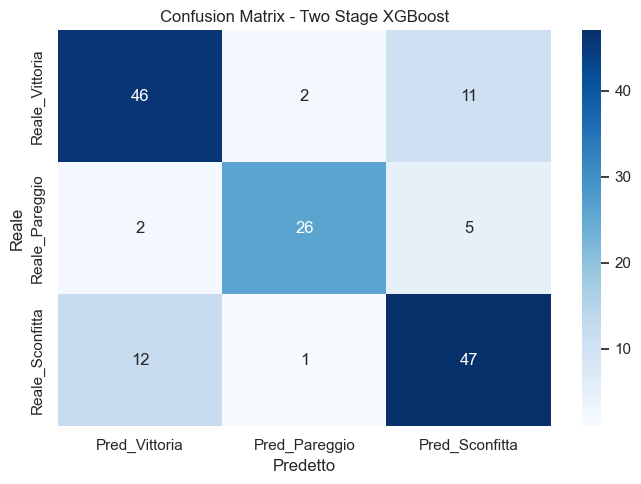

In [ ]:
# =========================================================
# MODELLO FINALE - TWO STAGE XGBOOST
# Versione pulita e coerente
# =========================================================



# =========================================================
# 1. DATASET BASE
# =========================================================
clf_df = features_df.copy()

# =========================================================
# 2. FEATURE PRIMITIVE PER SQUADRA
#    Usiamo solo variabili grezze, non diff/ratio già calcolate
# =========================================================
base_cols = [
    "BallRecovery",
    "Clearance",
    "Pass",
    "Tackle",
    "Interception",
    "Foul",
    "Card",
    "MissedShots",
    "ShotOnPost",
    "SavedShot",
    "Aerial",
    "TakeOn",
    "Saves",
    "mean_x",
    "mean_y",
    "mean_endX",
    "mean_endY",
    "total_shots",
    "shots_on_target"
]
base_cols = [c for c in base_cols if c in clf_df.columns]

# =========================================================
# 3. MERGE CON L'AVVERSARIO
# =========================================================
opp_df = clf_df[["match_id", "team_name"] + base_cols].copy()
opp_df = opp_df.rename(columns={"team_name": "opponent"})
opp_df = opp_df.rename(columns={c: f"{c}_opp" for c in base_cols})

clf_df = clf_df.merge(opp_df, on=["match_id", "opponent"], how="left")
clf_df = clf_df.rename(columns={c: f"{c}_team" for c in base_cols})

# =========================================================
# 4. FEATURE COMPARATIVE
# =========================================================
for col in base_cols:
    clf_df[f"{col}_diff"] = clf_df[f"{col}_team"] - clf_df[f"{col}_opp"]
    clf_df[f"{col}_diff_abs"] = clf_df[f"{col}_diff"].abs()
    clf_df[f"{col}_ratio"] = clf_df[f"{col}_team"] / (clf_df[f"{col}_opp"] + 1)

# =========================================================
# 5. FEATURE AGGREGATE SENSATE
# =========================================================
clf_df["attack_strength_team"] = (
    clf_df.get("total_shots_team", 0)
    + 2 * clf_df.get("shots_on_target_team", 0)
    + clf_df.get("ShotOnPost_team", 0)
    + clf_df.get("MissedShots_team", 0)
)

clf_df["attack_strength_opp"] = (
    clf_df.get("total_shots_opp", 0)
    + 2 * clf_df.get("shots_on_target_opp", 0)
    + clf_df.get("ShotOnPost_opp", 0)
    + clf_df.get("MissedShots_opp", 0)
)

clf_df["attack_strength_diff"] = clf_df["attack_strength_team"] - clf_df["attack_strength_opp"]
clf_df["attack_strength_diff_abs"] = clf_df["attack_strength_diff"].abs()

clf_df["defense_strength_team"] = (
    clf_df.get("Clearance_team", 0)
    + clf_df.get("Interception_team", 0)
    + clf_df.get("Tackle_team", 0)
    + clf_df.get("BallRecovery_team", 0)
)

clf_df["defense_strength_opp"] = (
    clf_df.get("Clearance_opp", 0)
    + clf_df.get("Interception_opp", 0)
    + clf_df.get("Tackle_opp", 0)
    + clf_df.get("BallRecovery_opp", 0)
)

clf_df["defense_strength_diff"] = clf_df["defense_strength_team"] - clf_df["defense_strength_opp"]
clf_df["defense_strength_diff_abs"] = clf_df["defense_strength_diff"].abs()

clf_df["shot_accuracy_team"] = clf_df.get("shots_on_target_team", 0) / (clf_df.get("total_shots_team", 0) + 1)
clf_df["shot_accuracy_opp"] = clf_df.get("shots_on_target_opp", 0) / (clf_df.get("total_shots_opp", 0) + 1)
clf_df["shot_accuracy_diff"] = clf_df["shot_accuracy_team"] - clf_df["shot_accuracy_opp"]
clf_df["shot_accuracy_diff_abs"] = clf_df["shot_accuracy_diff"].abs()

clf_df["pass_per_shot_team"] = clf_df.get("Pass_team", 0) / (clf_df.get("total_shots_team", 0) + 1)
clf_df["pass_per_shot_opp"] = clf_df.get("Pass_opp", 0) / (clf_df.get("total_shots_opp", 0) + 1)
clf_df["pass_per_shot_diff"] = clf_df["pass_per_shot_team"] - clf_df["pass_per_shot_opp"]

# =========================================================
# 6. FEATURE DI EQUILIBRIO PARTITA
# =========================================================
clf_df["total_shots_match"] = clf_df.get("total_shots_team", 0) + clf_df.get("total_shots_opp", 0)
clf_df["shots_on_target_match"] = clf_df.get("shots_on_target_team", 0) + clf_df.get("shots_on_target_opp", 0)
clf_df["passes_match"] = clf_df.get("Pass_team", 0) + clf_df.get("Pass_opp", 0)

clf_df["def_actions_match"] = (
    clf_df.get("Clearance_team", 0) + clf_df.get("Interception_team", 0) +
    clf_df.get("Tackle_team", 0) + clf_df.get("BallRecovery_team", 0) +
    clf_df.get("Clearance_opp", 0) + clf_df.get("Interception_opp", 0) +
    clf_df.get("Tackle_opp", 0) + clf_df.get("BallRecovery_opp", 0)
)

clf_df["shot_balance"] = clf_df["shots_on_target_diff_abs"] / (clf_df["shots_on_target_match"] + 1)
clf_df["territorial_balance"] = clf_df["mean_x_diff_abs"] + clf_df["mean_endX_diff_abs"]
clf_df["defensive_balance"] = clf_df["defense_strength_diff_abs"] / (clf_df["def_actions_match"] + 1)

# =========================================================
# 7. COSTRUZIONE X E y
# =========================================================
drop_cols = [
    "match_id", "team_name", "opponent",
    "result", "Goal", "goals", "goals_conceded", "points"
]
drop_cols = [c for c in drop_cols if c in clf_df.columns]

X_full = clf_df.drop(columns=drop_cols).copy()
X_full = X_full.select_dtypes(include=[np.number]).replace([np.inf, -np.inf], np.nan).fillna(0)
y_full = clf_df["result"].copy()

overview_df = pd.DataFrame({
    "Informazione": [
        "Numero osservazioni",
        "Numero feature disponibili",
        "Numero Vittorie",
        "Numero Sconfitte",
        "Numero Pareggi"
    ],
    "Valore": [
        X_full.shape[0],
        X_full.shape[1],
        (y_full == "Vittoria").sum(),
        (y_full == "Sconfitta").sum(),
        (y_full == "Pareggio").sum()
    ]
})

print("\n=== OVERVIEW DEL DATASET ===")
display(overview_df)

# =========================================================
# 8. TRAIN / VALIDATION / TEST
# =========================================================
X_temp, X_test_full, y_temp, y_test_full = train_test_split(
    X_full, y_full,
    test_size=0.20,
    random_state=42,
    stratify=y_full
)

X_train_full, X_val_full, y_train_full, y_val_full = train_test_split(
    X_temp, y_temp,
    test_size=0.125,   
    random_state=42,
    stratify=y_temp
)

# =========================================================
# 9. FEATURE FINALI
# =========================================================
stage1_features = [
    "total_shots_diff_abs",
    "shots_on_target_diff_abs",
    "Pass_diff_abs",
    "Tackle_diff_abs",
    "mean_x_diff_abs",
    "mean_endX_diff_abs",
    "shot_balance",
    "territorial_balance"
]
stage1_features = [c for c in stage1_features if c in X_train_full.columns]

stage2_features = [
    "attack_strength_diff",
    "defense_strength_diff",
    "shots_on_target_diff",
    "shot_accuracy_diff",
    "pass_per_shot_diff",
    "shots_on_target_team",
    "shots_on_target_opp",
    "Clearance_diff"
]
stage2_features = [c for c in stage2_features if c in X_train_full.columns]

max_len = max(len(stage1_features), len(stage2_features))
stage1_display = stage1_features + [""] * (max_len - len(stage1_features))
stage2_display = stage2_features + [""] * (max_len - len(stage2_features))

feature_summary_df = pd.DataFrame({
    "Stadio 1 - Pareggio vs Non Pareggio": stage1_display,
    "Stadio 2 - Vittoria vs Sconfitta": stage2_display
})
feature_summary_df.index = range(1, len(feature_summary_df) + 1)

display(feature_summary_df)

# =========================================================
# 10. DATASET PRIMO STADIO
# =========================================================
X_train_s1 = X_train_full[stage1_features].copy()
X_val_s1 = X_val_full[stage1_features].copy()
X_test_s1 = X_test_full[stage1_features].copy()

y_train_s1 = (y_train_full == "Pareggio").astype(int)
y_val_s1 = (y_val_full == "Pareggio").astype(int)
y_test_s1 = (y_test_full == "Pareggio").astype(int)

# =========================================================
# 11. DATASET SECONDO STADIO
# =========================================================
mask_train_s2 = y_train_full != "Pareggio"
mask_val_s2 = y_val_full != "Pareggio"
mask_test_s2 = y_test_full != "Pareggio"

X_train_s2 = X_train_full.loc[mask_train_s2, stage2_features].copy()
X_val_s2 = X_val_full.loc[mask_val_s2, stage2_features].copy()
X_test_s2 = X_test_full.loc[mask_test_s2, stage2_features].copy()

y_train_s2 = y_train_full[mask_train_s2].map({"Sconfitta": 0, "Vittoria": 1})
y_val_s2 = y_val_full[mask_val_s2].map({"Sconfitta": 0, "Vittoria": 1})
y_test_s2 = y_test_full[mask_test_s2].map({"Sconfitta": 0, "Vittoria": 1})

# =========================================================
# 12. FUNZIONE DI TUNING
# =========================================================
def tune_xgb(X_train, y_train, scale_pos_weight=None):
    param_grid = {
        "n_estimators": [300, 500, 700, 900],
        "max_depth": [3, 4, 5, 6],
        "learning_rate": [0.01, 0.03, 0.05, 0.08],
        "subsample": [0.7, 0.8, 0.9, 1.0],
        "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
        "min_child_weight": [1, 2, 3, 5, 7],
        "gamma": [0, 0.1, 0.3, 0.5],
        "reg_lambda": [1, 2, 5, 10]
    }

    model = XGBClassifier(
        objective="binary:logistic",
        random_state=42,
        eval_metric="logloss",
        tree_method="hist",
        scale_pos_weight=scale_pos_weight
    )

    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_grid,
        n_iter=25,
        cv=5,
        scoring="f1",
        n_jobs=-1,
        random_state=42,
        verbose=0
    )

    search.fit(X_train, y_train)
    return search.best_estimator_

# =========================================================
# 13. ADDESTRAMENTO MODELLI
# =========================================================
spw_s1 = (len(y_train_s1) - y_train_s1.sum()) / y_train_s1.sum()

best_s1 = tune_xgb(X_train_s1, y_train_s1, scale_pos_weight=spw_s1)
best_s2 = tune_xgb(X_train_s2, y_train_s2)

# =========================================================
# 14. RISULTATI DEL SECONDO MODELLO
# =========================================================
pred_val_s2 = best_s2.predict(X_val_s2)

second_model_metrics_df = pd.DataFrame({
    "Metrica": ["Accuracy", "Balanced Accuracy", "F1"],
    "Valore": [
        accuracy_score(y_val_s2, pred_val_s2),
        balanced_accuracy_score(y_val_s2, pred_val_s2),
        f1_score(y_val_s2, pred_val_s2)
    ]
}).round(4)

print("\n=== RISULTATI DEL SECONDO MODELLO (VITTORIA VS SCONFITTA) ===")
display(second_model_metrics_df)

second_model_report_df = pd.DataFrame(
    classification_report(y_val_s2, pred_val_s2, output_dict=True, zero_division=0)
).transpose().round(4)
display(second_model_report_df)

# =========================================================
# 15. OTTIMIZZAZIONE DELLA SOGLIA DEL PRIMO MODELLO SU VALIDATION
# =========================================================
proba_s1_val = best_s1.predict_proba(X_val_s1)[:, 1]
candidate_thresholds = np.arange(0.25,0.65, 0.01)

best_threshold = None
best_macro_val = -1

for thr in candidate_thresholds:
    preds_val = []

    for i in range(len(X_val_full)):
        proba_draw = proba_s1_val[i]

        if proba_draw >= thr:
            preds_val.append("Pareggio")

        elif proba_draw < (thr - 0.10):
            row_s2 = X_val_full.iloc[[i]][stage2_features]
            pred_s2 = best_s2.predict(row_s2)[0]
            preds_val.append("Vittoria" if pred_s2 == 1 else "Sconfitta")

        else:
            preds_val.append("Pareggio")

    macro_val = f1_score(
        y_val_full,
        preds_val,
        average="macro",
        zero_division=0
    )

    if macro_val > best_macro_val:
        best_macro_val = macro_val
        best_threshold = thr

threshold_val_df = pd.DataFrame({
    "Metrica": ["Soglia ottimale su validation", "Miglior F1 Macro su validation"],
    "Valore": [best_threshold, best_macro_val]
}).round(4)

print("\n=== OTTIMIZZAZIONE DELLA SOGLIA DEL PRIMO MODELLO ===")
display(threshold_val_df)

# =========================================================
# 16. RISULTATI DEL PRIMO MODELLO
# =========================================================
pred_val_s1 = (proba_s1_val >= best_threshold).astype(int)

first_model_metrics_df = pd.DataFrame({
    "Metrica": ["Balanced Accuracy"],
    "Valore": [balanced_accuracy_score(y_val_s1, pred_val_s1)]
}).round(4)

print("\n=== RISULTATI DEL PRIMO MODELLO (PAREGGIO VS NON PAREGGIO) ===")
display(first_model_metrics_df)

first_model_report_df = pd.DataFrame(
    classification_report(
        y_val_s1,
        pred_val_s1,
        target_names=["Non Pareggio", "Pareggio"],
        output_dict=True,
        zero_division=0
    )
).transpose().round(4)
display(first_model_report_df)

# =========================================================
# 17. RISULTATI FINALI DEL MODELLO TWO-STAGE SU TEST
# =========================================================
proba_s1_test = best_s1.predict_proba(X_test_s1)[:, 1]

best_pred_final = []

for i in range(len(X_test_full)):
    if proba_s1_test[i] >= best_threshold:
        best_pred_final.append("Pareggio")
    else:
        row_s2 = X_test_full.iloc[[i]][stage2_features]
        pred_s2 = best_s2.predict(row_s2)[0]
        best_pred_final.append("Vittoria" if pred_s2 == 1 else "Sconfitta")

final_metrics_df = pd.DataFrame({
    "Metrica": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision Macro",
        "Recall Macro",
        "F1 Macro",
        "F1 Weighted"
    ],
    "Valore": [
        accuracy_score(y_test_full, best_pred_final),
        balanced_accuracy_score(y_test_full, best_pred_final),
        precision_score(y_test_full, best_pred_final, average="macro", zero_division=0),
        recall_score(y_test_full, best_pred_final, average="macro", zero_division=0),
        f1_score(y_test_full, best_pred_final, average="macro", zero_division=0),
        f1_score(y_test_full, best_pred_final, average="weighted", zero_division=0)
    ]
}).round(4)

print("\n=== RISULTATI FINALI DEL MODELLO TWO-STAGE ===")
display(final_metrics_df)

final_report_df = pd.DataFrame(
    classification_report(y_test_full, best_pred_final, output_dict=True, zero_division=0)
).transpose().round(4)
display(final_report_df)

# =========================================================
# 18. MATRICE DI CONFUSIONE FINALE
# =========================================================
cm_df = pd.DataFrame(
    confusion_matrix(
        y_test_full,
        best_pred_final,
        labels=["Vittoria", "Pareggio", "Sconfitta"]
    ),
    index=["Reale_Vittoria", "Reale_Pareggio", "Reale_Sconfitta"],
    columns=["Pred_Vittoria", "Pred_Pareggio", "Pred_Sconfitta"]
)

print("\n=== MATRICE DI CONFUSIONE FINALE ===")
display(cm_df)

plt.figure(figsize=(7, 5))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - Two Stage XGBoost")
plt.xlabel("Predetto")
plt.ylabel("Reale")
plt.tight_layout()
plt.show()     

# Risultati dei modelli

## Modello 1 — Pareggio vs Non Pareggio

Il primo modello, dedicato alla classificazione del pareggio, mostra prestazioni molto elevate.

- Balanced Accuracy: 0.9452  
- Accuracy: 0.9474  

Analizzando le metriche per classe:

- Non Pareggio
  - Precision: 0.9825
  - Recall: 0.9492
  - F1-score: 0.9655  

- Pareggio
  - Precision: 0.8421
  - Recall: 0.9412
  - F1-score: 0.8889  

Il modello risulta particolarmente efficace nel riconoscere i pareggi (recall elevato), riuscendo quindi a identificare la maggior parte delle partite equilibrate.

Le prestazioni elevate di questo modello sono spiegabili dalla natura stessa delle feature utilizzate.  
Le variabili selezionate descrivono infatti il grado di equilibrio tra le due squadre (differenze assolute su tiri, passaggi, posizione e attività difensiva).  

Quando queste differenze sono basse, la partita tende ad essere bilanciata, e quindi più probabilmente un pareggio.  
Quando invece le differenze sono elevate, il modello riconosce facilmente situazioni di non equilibrio, associandole a vittoria o sconfitta.

Questo rende il problema più semplice rispetto a una classificazione multiclass diretta, poiché il modello deve distinguere principalmente tra:
- partite equilibrate  
- partite non equilibrate  

Di conseguenza, la separabilità tra le classi risulta elevata, portando a performance molto alte.

## Modello 2 — Vittoria vs Sconfitta

Il secondo modello, applicato solo alle partite classificate come "non pareggio", distingue tra vittoria e sconfitta.

- Accuracy: 0.8136  
- Balanced Accuracy: 0.8138  
- F1-score: 0.8136  

Metriche per classe:

- Classe 0
  - Precision: 0.8000
  - Recall: 0.8276
  - F1-score: 0.8136  

- Classe 1
  - Precision: 0.8276
  - Recall: 0.8000
  - F1-score: 0.8136  

Le prestazioni risultano bilanciate tra le due classi, indicando che il modello è in grado di distinguere in modo consistente tra vittoria e sconfitta.


## Modello finale Two-Stage

Combinando i due modelli si ottiene una classificazione a tre classi: vittoria, pareggio e sconfitta.

- Accuracy: 0.7829  
- Balanced Accuracy: 0.7836  
- F1 Macro: 0.7920  

Metriche per classe:

- Pareggio
  - Precision: 0.8966
  - Recall: 0.7879
  - F1-score: 0.8387  

- Sconfitta
  - Precision: 0.7460
  - Recall: 0.7833
  - F1-score: 0.7642  

- Vittoria
  - Precision: 0.7667
  - Recall: 0.7797
  - F1-score: 0.7731  

Questi risultati confermano la validità dell’approccio two-stage, in quanto il modello riesce a distinguere efficacemente tra partite equilibrate e non equilibrate, mantenendo al contempo buone prestazioni nella distinzione tra vittoria e sconfitta.


## Analisi della matrice di confusione

- I pareggi vengono riconosciuti correttamente nella maggior parte dei casi (26 su 33).
- Gli errori principali avvengono tra vittoria e sconfitta.
- Alcune vittorie vengono classificate come sconfitte e viceversa.
- Gli errori sul pareggio sono limitati, confermando la bontà delle feature di equilibrio.


## Considerazioni finali

L’approccio two-stage consente di separare efficacemente:
- il riconoscimento delle partite equilibrate  
- la distinzione tra superiorità di una squadra  

Il primo stadio risulta più semplice e performante, mentre il secondo rappresenta la parte più complessa del problema.

## Limiti del modello

Nonostante le buone prestazioni, il modello presenta alcune limitazioni.

Gli errori residui si concentrano principalmente nella distinzione tra vittoria e sconfitta, che rappresenta una separazione più complessa rispetto al riconoscimento del pareggio.

Inoltre, il modello si basa esclusivamente su feature aggregate derivate dagli eventi di gioco e non tiene conto di altri fattori potenzialmente rilevanti, come:
- la qualità intrinseca delle squadre
- il contesto specifico della partita
- informazioni temporali più dettagliate sugli eventi

Questi aspetti potrebbero essere oggetto di sviluppi futuri.

## Conclusioni

Il progetto ha permesso di affrontare in modo completo il problema della predizione del risultato di una partita a partire da dati evento, inizialmente non strutturati.

Attraverso una fase di interpretazione del dataset e di costruzione delle feature, è stato possibile trasformare informazioni a livello di singolo evento in variabili rappresentative del comportamento delle squadre.

L’approccio adottato, basato su una classificazione two-stage, si è dimostrato efficace sia dal punto di vista delle prestazioni che dell’interpretabilità, risultando coerente con la struttura reale del gioco del calcio.

Nel complesso, il lavoro evidenzia come una buona progettazione delle feature e una corretta formulazione del problema siano elementi fondamentali per ottenere modelli predittivi solidi e significativi.